# Experiências — Projeto 1

Aqui reunimos as medições, a análise e as decisões de desempenho. As validações estão em `projeto1.ipynb` (10%) e `validacao_completa.ipynb` (100%). O conjunto principal é 2023+2024; 2022 entra apenas na comparação de dimensão.

Este notebook lê os ficheiros de `experiencias/resultados`. Executar as células atualiza as tabelas e os gráficos; não lança a pipeline nem cria uma sessão Spark. Os comandos das novas corridas estão nos blocos PowerShell de cada experiência.

Ordem de leitura: **método → medições controladas → escala → síntese → arquivo exploratório**. O arquivo final conserva o código e as saídas das comparações antigas, separados das três repetições por configuração.


## Como consultar

- Secções 1–4: dados, ambiente e âmbito dos tempos.
- Secções 5–6: teste de funcionamento e referência sem cache.
- Secções 7–11: cache, O1, joins, AQE e partições de shuffle.
- Secções 12–13: escala por workers e dimensão dos dados.
- Secção 14: síntese das escolhas para o relatório.
- Secção 15: arquivo das medições exploratórias retiradas dos notebooks de validação.


## 1. Preparar a leitura das métricas

Usar o kernel Python do nosso Jupyter. Os ficheiros pequenos de métricas estão separados dos dados e dos Parquet analíticos.


In [1]:
from pathlib import Path
import json
import pandas as pd

project = Path("/project") if Path("/project/projeto1.py").is_file() else Path.cwd()
if not (project / "projeto1.py").is_file():
    project = project / "PROJETO1"

results_folder = project / "experiencias" / "resultados"
test_folder = results_folder / "verificacao_medicao_01"

with (test_folder / "run_info.json").open(encoding="utf-8") as file:
    test_info = json.load(file)
with (test_folder / "profile_metrics.json").open(encoding="utf-8") as file:
    test_metrics = json.load(file)

print("Métricas lidas:", test_folder.name)


Métricas lidas: verificacao_medicao_01


## 2. Dados e percurso da pipeline

Usamos os 12 meses de 2023 e os 12 meses de 2024, mais a tabela de zonas. A fração é uma amostra das viagens, não uma seleção de meses. Mesmo com 1%, a leitura pode ter de percorrer os ficheiros.

| Fração | Finalidade |
|---|---|
| 1% | Testar o comando, as escritas e a recolha das métricas |
| 10% | Validar e investigar com menos dados |
| 100% | Validar o conjunto completo e realizar as medições finais |

| Etapa | Organização dos dados |
|---|---|
| M1 | Meses unidos, tipos comuns, contagem dos problemas e viagens limpas |
| M2 | Borough × dia da semana × hora: volume e médias |
| M3 | Zona × ano × mês: estatísticas, ranking e janelas |
| O1 | Referência por zona × hora; taxas por borough, pagamento e tipo de dia |
| O2 | Origem × destino × ano × mês: participações, top e inversões |

### Schema: preparar os meses para os juntar

O **schema** define os nomes e tipos das colunas. Não define o número de partições.

- Selecionamos só as oito colunas usadas na pipeline. Em Parquet, isto permite evitar a leitura das outras colunas.
- Lemos mês a mês porque, por exemplo, `passenger_count` pode ter um tipo físico diferente entre ficheiros. Convertemos os campos para os tipos comuns definidos em `TRIP_COLS`.
- `try_cast` tenta converter o valor; se a conversão for inválida, devolve `null`, que contamos em `f_nulls`. Não elimina a viagem nessa operação: a exclusão acontece na limpeza.
- `unionByName` acrescenta as linhas dos meses, alinhando as colunas pelo nome. Não é um `join` por identificador e não remove duplicados.

Exemplo: depois de uniformizar os tipos, juntar janeiro e fevereiro significa colocar as viagens dos dois meses na mesma tabela lógica. Isso não junta duas viagens numa só nem obriga a guardar tudo numa única partição.

### Por que escolhemos O1 e O2?

**O1** permite comparar uma janela sobre milhões de viagens com uma pequena tabela de médias/desvios por zona e hora, junta de volta por broadcast. Testamos se muda o custo de shuffle e ordenação, mantendo a regra de anomalia.

**O2** exige agregação por origem/destino/ano/mês, cálculo de participações e duas junções à tabela de zonas. Permite estudar shuffle e estratégia de junção. Não medimos outras ordens dessas junções.

As 6312 linhas finais de M3 não significam que M3 só processa 6312 linhas: a agregação inicial continua a consumir as viagens. A cache evita repetir cálculos anteriores; não transforma a tabela limpa numa tabela agregada.


## 3. Ambiente e configuração do teste

A referência usa três workers de dois cores no Docker, todos no mesmo PC. Cada worker anuncia 2 GiB ao Spark; cada executor pede 1536 MiB. A análise de escala varia apenas o número de workers, mantendo estes valores por worker.

A tabela seguinte lê as opções do teste inicial de funcionamento. O hardware observado, os limites do Docker e os IDs das imagens estão na secção 12.1 e em `experiencias/resultados/ambiente_escala.json`.

**Porquê Docker?** Não escolhemos Docker em vez de cores: os contentores usam os cores e a memória do PC. O cluster Docker segue as Labs e satisfaz o mínimo de cluster pedido no enunciado; permite estudar workers, executors e comunicação entre processos. `local[*]` usaria os cores da mesma máquina sem workers Spark separados. Não comparámos os dois modos no mesmo PC, logo não demonstrámos que Docker seja mais rápido. A escolha do ambiente é uma decisão de montagem; as hipóteses testadas são os efeitos de cache, joins, AQE, partições e recursos.


In [2]:
configuration = pd.DataFrame([
    {"option": "Spark", "value": test_info["spark_version"]},
    {"option": "Master", "value": test_info["master"]},
    {"option": "Paralelismo", "value": test_info["parallelism"]},
    {"option": "Memória por executor", "value": test_info["executor_memory"]},
    {"option": "Partições de shuffle", "value": test_info["shuffle_partitions"]},
    {"option": "Fração", "value": test_info["fraction"]},
    {"option": "Cache Spark", "value": test_info["cache"]},
    {"option": "Broadcast das zonas", "value": test_info["broadcast"]},
    {"option": "AQE", "value": test_info["aqe"]},
    {"option": "Método O1", "value": test_info["o1_method"]}
])
configuration


,option,value
0,Spark,4.2.0
1,Master,spark://spark-master:7077
2,Paralelismo,6
3,Memória por executor,1536m
4,Partições de shuffle,200
5,Fração,0.01
6,Cache Spark,False
7,Broadcast das zonas,True
8,AQE,True
9,Método O1,groupby


## 4. O que medimos

`total_s` mede o tempo desde a leitura até à última escrita, incluindo os CSV. O arranque da sessão Spark fica separado. A recolha e exportação das métricas também ficam fora do tempo da pipeline.

A soma dos blocos parciais não substitui o tempo global: pode deixar de fora preparação, planeamento e escritas locais. Os tempos acumulados dos executors somam trabalho em paralelo e não são iguais ao tempo de espera no PC.

Para comparar cache, incluímos o custo de a preencher. A cache do Spark é diferente da cache de ficheiros do sistema operativo.

O profiler agrega os stages associados ao bloco; não guarda os tempos de cada tarefa. `input_bytes` pode incluir leituras da cache e não equivale aos bytes físicos lidos do disco. O spill de execução também não é o espaço ocupado pela cache. Stages reutilizados, tentativas e retenção da Spark UI exigem cuidado ao interpretar estas somas. O helper usa unidades de 1024 bytes, embora apresente os rótulos KB/MB/GB.

**Níveis de medição:** o tempo da pipeline mede a execução completa; o tempo de um módulo inclui o seu cálculo e a escrita/recolha; a duração de um stage localiza uma etapa; a distribuição das durações das tarefas ajuda a detetar desequilíbrio. Não recolhemos essa distribuição nas experiências guardadas, por isso não afirmamos ter demonstrado skew nem que a maioria das tarefas estava vazia.

**Ablação:** comparamos a configuração escolhida com uma variante em que uma opção foi desligada, mantendo as restantes constantes. Na experiência de cache, apresentamos a mesma comparação no sentido sem cache → com cache. O objetivo é isolar o efeito observado dessa opção; não somamos as melhorias das várias comparações.


## 5. Teste de funcionamento — 1%

Esta corrida executou M1, M2, M3, O1 e O2, com todas as escritas. Serve para confirmar o funcionamento da medição, não para concluir qual a versão mais rápida.

Foi lançada no PowerShell, na pasta do projeto:

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 0.01 --no-cache --output /project/data/experiencias/verificacao_medicao_01
```

As tabelas abaixo são lidas dos ficheiros reais dessa corrida, sem introduzir números à mão.


In [3]:
test_summary = pd.DataFrame([{
    "run": test_folder.name,
    "fraction": test_info["fraction"],
    "files": test_info["files"],
    "clean_rows": test_info["clean_rows"],
    "total_s": test_info["total_s"],
    "timed_blocks_sum_s": test_info["timed_blocks_sum_s"],
    "spark_startup_s": test_info["spark_startup_s"],
    "jobs": test_metrics["num_jobs"],
    "stages": test_metrics["num_stages"],
    "tasks": test_metrics["num_tasks"]
}])
test_summary


,run,fraction,files,clean_rows,total_s,timed_blocks_sum_s,spark_startup_s,jobs,stages,tasks
0,verificacao_medicao_01,0.01,24,702761,62.877,49.67,3.592,75,136,4490


In [4]:
# MiB = bytes / 1024². Os valores originais ficam nos JSON.
traffic = pd.DataFrame([
    {"metric": name, "MiB": round(test_metrics[name] / 1024**2, 3)}
    for name in ["input_bytes", "output_bytes", "shuffle_read_bytes",
                 "shuffle_write_bytes", "memory_spilled_bytes", "disk_spilled_bytes"]
])
traffic


,metric,MiB
0,input_bytes,8.882
1,output_bytes,1.082
2,shuffle_read_bytes,30.187
3,shuffle_write_bytes,26.412
4,memory_spilled_bytes,0.000
5,disk_spilled_bytes,0.000


In [5]:
partial_times = pd.DataFrame(
    list(test_info["timings_s"].items()), columns=["block", "seconds"]
)
partial_times


,block,seconds
0,M1_stats,7.06
1,M1_clean_count,3.70
2,M2_write,7.52
3,M3_write,8.33
4,O1_rates,8.37
5,O2_routes_write,5.26
6,O2_reversal_write,5.22
7,O2_top,4.21


Conclusão deste teste: o comando percorreu a pipeline e produziu os ficheiros de resultados e de métricas. O tempo global foi maior do que a soma dos blocos, por isso usamos `total_s` na comparação completa.

As três corridas sem cache com 100% dos dados estão na secção 6.


## 6. Baseline completa — três corridas sem cache

Configuração inicial: 100% dos dados, três workers, 1536 MiB por executor, sem cache Spark, broadcast das zonas e AQE ativos, O1 por groupBy. Esta é a baseline inicial. Depois do teste de cache, as experiências de O1, joins, AQE e partições usam as três corridas com cache como referência comum. As melhorias dessas experiências não se somam.

O groupBy de O1 também usa broadcast das estatísticas. `--no-broadcast` controla só as junções com as zonas.

Comando usado na primeira corrida:

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 1.0 --no-cache --output /project/data/experiencias/baseline_sem_cache_01
```

Cada repetição usa uma aplicação Spark nova e uma pasta própria (`_01`, `_02`, `_03`). Não correr outros notebooks Spark ao mesmo tempo. Registar o hardware, as configurações e as condições do PC. Não eliminar tempos lentos sem explicar a razão.


### 6.1 Resultados das corridas sem cache

As três corridas usaram a mesma configuração e deram 70 353 039 viagens válidas. A comparação com cache está na secção 7.


In [6]:
# Ler as corridas completas sem cache, separadas do teste de 1%.
baseline_runs = []
for folder in sorted(results_folder.glob("baseline_sem_cache_*")):
    with (folder / "run_info.json").open(encoding="utf-8") as file:
        info = json.load(file)
    with (folder / "profile_metrics.json").open(encoding="utf-8") as file:
        metrics = json.load(file)
    baseline_runs.append({
        "run": folder.name,
        "fraction": info["fraction"],
        "cache": info["cache"],
        "clean_rows": info["clean_rows"],
        "total_s": info["total_s"],
        "stages": metrics["num_stages"],
        "tasks": metrics["num_tasks"],
        "shuffle_read_MiB": round(metrics["shuffle_read_bytes"] / 1024**2, 2),
        "shuffle_write_MiB": round(metrics["shuffle_write_bytes"] / 1024**2, 2),
        "disk_spill_MiB": round(metrics["disk_spilled_bytes"] / 1024**2, 2)
    })
baseline_table = pd.DataFrame(baseline_runs)
baseline_table


,run,fraction,cache,clean_rows,total_s,stages,tasks,shuffle_read_MiB,shuffle_write_MiB,disk_spill_MiB
0,baseline_sem_cache_01,1.0,False,70353039,101.269,135,4461,129.92,113.25,0.0
1,baseline_sem_cache_02,1.0,False,70353039,103.528,135,4461,129.95,113.28,0.0
2,baseline_sem_cache_03,1.0,False,70353039,100.620,135,4461,129.91,113.24,0.0


### 6.2 Resumo das três repetições

A mediana é o tempo do meio e é menos sensível a uma corrida invulgar. Não substitui os outros resultados: mostramos também a média, os três tempos e a amplitude (máximo menos mínimo). Com apenas três repetições, evitamos conclusões gerais.


In [7]:
# Resumir as repetições, mantendo também os tempos individuais.
baseline_summary = pd.DataFrame([{
    "configuration": "Sem cache Spark",
    "repetitions": len(baseline_table),
    "mean_s": baseline_table["total_s"].mean(),
    "median_s": baseline_table["total_s"].median(),
    "minimum_s": baseline_table["total_s"].min(),
    "maximum_s": baseline_table["total_s"].max(),
    "range_s": round(baseline_table["total_s"].max() - baseline_table["total_s"].min(), 3)
}])
baseline_summary


,configuration,repetitions,mean_s,median_s,minimum_s,maximum_s,range_s
0,Sem cache Spark,3,101.805667,101.269,100.62,103.528,2.908


## 7. Experiência de cache

**Problema/evidência:** As mesmas viagens limpas alimentam vários módulos; sem persistência, o plano pode voltar a ler e limpar a origem.

Hipótese: as viagens limpas são reutilizadas em vários módulos, por isso guardar esse DataFrame pode evitar trabalho repetido. O ganho tem de compensar o preenchimento da cache.

Retirámos apenas `--no-cache`. Mantivemos os 24 ficheiros de 2023/2024, 100% dos dados, três workers, seis cores, 1536 MiB por executor, 200 partições de shuffle, AQE e broadcast das zonas ativos e O1 por groupBy. Cada corrida criou uma aplicação Spark nova. O tempo inclui preencher a cache e todas as escritas; exclui o arranque do Spark e a recolha das métricas.

Comando da primeira repetição (nas seguintes, mudar `_01` para `_02` e `_03`):

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 1.0 --output /project/data/experiencias/baseline_com_cache_01
```

### 7.1 Tempos individuais


In [8]:
# Ler as três corridas com cache e juntar à referência.
cache_runs = []
for folder in sorted(results_folder.glob("baseline_com_cache_*")):
    info = json.loads((folder / "run_info.json").read_text(encoding="utf-8"))
    metrics = json.loads((folder / "profile_metrics.json").read_text(encoding="utf-8"))
    cache_runs.append({
        "run": folder.name, "cache": info["cache"],
        "clean_rows": info["clean_rows"], "total_s": info["total_s"],
        "stages": metrics["num_stages"], "tasks": metrics["num_tasks"],
        "shuffle_read_MiB": metrics["shuffle_read_bytes"] / 1024**2,
        "shuffle_write_MiB": metrics["shuffle_write_bytes"] / 1024**2,
        "disk_spill_MiB": metrics["disk_spilled_bytes"] / 1024**2
    })
cache_table = pd.DataFrame(cache_runs)
assert len(baseline_table) == len(cache_table) == 3
cache_comparison = pd.concat([baseline_table, cache_table], ignore_index=True)
assert cache_comparison["clean_rows"].eq(70353039).all()
cache_comparison[["run", "cache", "clean_rows", "total_s", "stages", "tasks"]]


,run,cache,clean_rows,total_s,stages,tasks
0,baseline_sem_cache_01,False,70353039,101.269,135,4461
1,baseline_sem_cache_02,False,70353039,103.528,135,4461
2,baseline_sem_cache_03,False,70353039,100.620,135,4461
3,baseline_com_cache_01,True,70353039,74.981,142,5469
4,baseline_com_cache_02,True,70353039,76.861,142,5469
5,baseline_com_cache_03,True,70353039,79.109,142,5469


### 7.2 Média e mediana

Usamos a mediana no cálculo da melhoria e deixamos a média ao lado para perceber se a conclusão depende desse resumo.


In [9]:
# Resumir os dois conjuntos sem esconder os tempos individuais.
cache_summary = cache_comparison.groupby("cache")["total_s"].agg(
    repetitions="count", mean_s="mean", median_s="median",
    minimum_s="min", maximum_s="max"
)
cache_summary["range_s"] = cache_summary["maximum_s"] - cache_summary["minimum_s"]
median_gain = 100 * (1 - cache_summary.loc[True, "median_s"] / cache_summary.loc[False, "median_s"])
mean_gain = 100 * (1 - cache_summary.loc[True, "mean_s"] / cache_summary.loc[False, "mean_s"])
print(f"Redução pela mediana: {median_gain:.1f}%")
print(f"Redução pela média: {mean_gain:.1f}%")
cache_summary.round(3)


Redução pela mediana: 24.1%
Redução pela média: 24.4%


,repetitions,mean_s,median_s,minimum_s,maximum_s,range_s
cache,,,,,,
False,3,101.806,101.269,100.620,103.528,2.908
True,3,76.984,76.861,74.981,79.109,4.128


### 7.3 Resultados preservados

Depois das medições, lemos as sete tabelas produzidas por cada corrida com cache e comparámos com `baseline_sem_cache_01`. Alinhámos pelas chaves, sem depender da ordem das linhas ou das partições. Confirmámos as chaves e colunas, ausência de chaves repetidas e presença de `_SUCCESS` nas quatro escritas Parquet.

Contagens, texto, valores decimais, rankings e classificações são comparados exatamente. Para valores de vírgula flutuante, aceitámos `atol=1e-9` e `rtol=1e-12`, tratando dois nulos como iguais. Nesta comparação, a diferença máxima observada foi zero. O script da verificação fica em `data/experiencias/verificar_cache.py`; o resumo está em `experiencias/resultados/comparacao_cache_resultados.json`.


In [10]:
# Mostrar a verificação das sete tabelas nas três repetições.
cache_checks = pd.read_json(results_folder / "comparacao_cache_resultados.json")
assert len(cache_checks) == 21
assert cache_checks["differences"].eq(0).all()
cache_checks


,run,table,rows,differences,max_float_difference
0,baseline_com_cache_01,m1_cleaning_stats.csv,2,0,0
1,baseline_com_cache_02,m1_cleaning_stats.csv,2,0,0
2,baseline_com_cache_03,m1_cleaning_stats.csv,2,0,0
3,baseline_com_cache_01,m2_demand,995,0,0
4,baseline_com_cache_02,m2_demand,995,0,0
5,baseline_com_cache_03,m2_demand,995,0,0
6,baseline_com_cache_01,m3_zone_month,6312,0,0
7,baseline_com_cache_02,m3_zone_month,6312,0,0
8,baseline_com_cache_03,m3_zone_month,6312,0,0
9,baseline_com_cache_01,o1_anomaly_rates.csv,48,0,0


### 7.4 O que concluímos

A mediana passou de 101.269 s sem cache para 76.861 s com cache: menos 24.1%. A média passou de 101.806 s para 76.984 s. As três corridas com cache foram mais rápidas do que as três sem cache e preservaram os resultados verificados. Para esta pipeline e este ambiente, mantemos a cache das viagens limpas.

Ter mais tarefas não impediu um tempo menor. Os bytes de entrada reportados não são usados isoladamente como prova de leituras físicas do disco, porque os planos com e sem cache são diferentes. Spill de execução igual a zero também não prova que toda a cache ficou em RAM.

A ordem real foi: três corridas sem cache, seguidas de três com cache. Não alternámos a ordem nem limpámos a cache de ficheiros do sistema operativo. Esta limitação e as poucas repetições impedem atribuir toda a diferença apenas à cache Spark ou garantir o mesmo ganho noutro PC. Numa confirmação futura, convém alternar a ordem.


## 8. O1 — groupBy ou janela?

**Problema/evidência:** A janela precisa de organizar as viagens por zona e hora. A variante groupBy reduz primeiro as estatísticas por grupo.

Hipótese: calcular a média e o desvio por grupo e juntar as pequenas estatísticas por broadcast pode ser mais leve do que aplicar janelas às viagens todas. A alternativa usa `Window.partitionBy(PULocationID, hour_of_day)`. Na versão groupBy, usamos `groupBy(...).agg(...)` e `join(broadcast(stats), ...)`. O limite de anomalia é o mesmo: média + 3 × desvio-padrão.

Mudámos só `--o1-method window`, mantendo cache, AQE, broadcast das zonas, 200 partições de shuffle, memória, três workers/seis cores e 100% dos mesmos 24 ficheiros. Reutilizamos as três corridas `baseline_com_cache_*` como referência groupBy e fazemos três aplicações novas com janela. Medimos a pipeline completa e mostramos também o bloco O1, sem confundir esse bloco com o total.

Comando da primeira corrida (repetir com pastas `_02` e `_03`):

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 1.0 --o1-method window --output /project/data/experiencias/o1_window_cache_01
```

### 8.1 As seis medições


In [11]:
# Ler as medições guardadas; esta célula não executa Spark.
o1_runs = []
for pattern in ["baseline_com_cache_*", "o1_window_cache_*"]:
    for folder in sorted(results_folder.glob(pattern)):
        info = json.loads((folder / "run_info.json").read_text(encoding="utf-8"))
        metrics = json.loads((folder / "profile_metrics.json").read_text(encoding="utf-8"))
        o1_runs.append({
            "run": folder.name, "method": info["o1_method"],
            "clean_rows": info["clean_rows"], "total_s": info["total_s"],
            "O1_s": info["timings_s"]["O1_rates"],
            "stages": metrics["num_stages"], "tasks": metrics["num_tasks"],
            "shuffle_read_MiB": metrics["shuffle_read_bytes"] / 1024**2,
            "shuffle_write_MiB": metrics["shuffle_write_bytes"] / 1024**2,
            "disk_spill_MiB": metrics["disk_spilled_bytes"] / 1024**2
        })
o1_table = pd.DataFrame(o1_runs)
assert len(o1_table) == 6 and o1_table["clean_rows"].eq(70353039).all()
o1_table.round(3)


,run,method,clean_rows,total_s,O1_s,stages,tasks,shuffle_read_MiB,shuffle_write_MiB,disk_spill_MiB
0,baseline_com_cache_01,groupby,70353039,74.981,5.20,142,5469,129.910,129.659,0.000
1,baseline_com_cache_02,groupby,70353039,76.861,5.10,142,5469,130.084,129.833,0.000
2,baseline_com_cache_03,groupby,70353039,79.109,5.44,142,5469,130.073,129.822,0.000
3,o1_window_cache_01,window,70353039,81.240,12.00,143,5378,955.480,955.399,660.778
4,o1_window_cache_02,window,70353039,83.298,13.20,143,5378,955.566,955.485,660.745
5,o1_window_cache_03,window,70353039,85.165,12.68,143,5378,955.371,955.291,665.038


### 8.2 Resumo dos tempos

As métricas de tarefas e shuffle da tabela anterior abrangem a pipeline toda. O tempo `O1_s` mede apenas o bloco que calcula e recolhe as taxas de O1.


In [12]:
# Comparar média e mediana do total e do bloco O1.
o1_summary = o1_table.groupby("method").agg(
    repetitions=("total_s", "count"), mean_total_s=("total_s", "mean"),
    median_total_s=("total_s", "median"), min_total_s=("total_s", "min"),
    max_total_s=("total_s", "max"), mean_O1_s=("O1_s", "mean"),
    median_O1_s=("O1_s", "median"),
    median_shuffle_write_MiB=("shuffle_write_MiB", "median"),
    median_disk_spill_MiB=("disk_spill_MiB", "median")
)
assert o1_summary["repetitions"].eq(3).all()
o1_summary.round(3)


,repetitions,mean_total_s,median_total_s,min_total_s,max_total_s,mean_O1_s,median_O1_s,median_shuffle_write_MiB,median_disk_spill_MiB
method,,,,,,,,,
groupby,3,76.984,76.861,74.981,79.109,5.247,5.20,129.822,0.000
window,3,83.234,83.298,81.240,85.165,12.627,12.68,955.399,660.778


### 8.3 Conferir os resultados

Comparamos as sete tabelas de cada corrida com janela com `baseline_com_cache_01`, alinhadas pelas chaves. A verificação usa as mesmas regras da experiência de cache: contagens, decimais, rankings e classificações exatos; valores float com tolerância absoluta `1e-9` e relativa `1e-12`. Isto confere os resultados finais, incluindo as contagens de anomalias por grupo; a comparação de classificações por viagem está nos notebooks de validação.


In [13]:
o1_checks = pd.read_json(results_folder / "comparacao_o1_resultados.json")
assert len(o1_checks) == 21 and o1_checks["differences"].eq(0).all()
o1_checks


,run,table,rows,differences,max_float_difference
0,o1_window_cache_01,m1_cleaning_stats.csv,2,0,0
1,o1_window_cache_02,m1_cleaning_stats.csv,2,0,0
2,o1_window_cache_03,m1_cleaning_stats.csv,2,0,0
3,o1_window_cache_01,m2_demand,995,0,0
4,o1_window_cache_02,m2_demand,995,0,0
5,o1_window_cache_03,m2_demand,995,0,0
6,o1_window_cache_01,m3_zone_month,6312,0,0
7,o1_window_cache_02,m3_zone_month,6312,0,0
8,o1_window_cache_03,m3_zone_month,6312,0,0
9,o1_window_cache_01,o1_anomaly_rates.csv,48,0,0


### 8.4 Decisão

Mediana da pipeline: groupBy 76.861 s; janela 83.298 s. Mediana do bloco O1: groupBy 5.20 s; janela 12.68 s. A versão groupBy reduziu o total em 7.7% face à janela e o bloco O1 em 59.0%. Os resultados finais coincidiram nas 21 comparações. Mantemos groupBy neste ambiente.

A mediana de shuffle escrito na pipeline foi 129.8 MiB com groupBy e 955.4 MiB com janela. O spill em disco passou de 0.0 para 660.8 MiB. Estes valores são compatíveis com maior custo de redistribuição e ordenação na alternativa com janela; são métricas da execução completa, não apenas do operador Window.

As corridas groupBy foram feitas antes das corridas com janela, sem alternar a ordem nem controlar a cache de ficheiros do sistema. São três repetições por método no mesmo PC, não uma garantia para todos os dados ou clusters. O tempo total também inclui os outros módulos, pelo que não atribuímos toda a variação ao bloco O1.


## 9. Junções com as zonas — broadcast ou sort-merge?

**Problema/evidência:** Os planos da alternativa merge mostram Exchange e Sort; a tabela de zonas tem apenas 265 linhas.

Hipótese: como a tabela de zonas é pequena, enviá-la aos executors por broadcast pode evitar redistribuir as viagens para a junção. Com sort-merge, as duas entradas são organizadas pela chave antes da junção.

Mudámos só `--no-broadcast`. No nosso código, esta opção aplica `.hint("merge")` à tabela de zonas; não significa apenas deixar de forçar broadcast. Afeta as junções pickup de M2/M3/O1 e as junções pickup/dropoff de O2. O broadcast das estatísticas de O1 por groupBy continua ativo.

Mantivemos 100% dos 24 ficheiros de 2023/2024, cache, O1 por groupBy, AQE, 200 partições de shuffle, três workers/seis cores e 1536 MiB por executor. A referência broadcast são as três pastas `baseline_com_cache_*`, sem duplicar medições. A alternativa fica em `zonas_sortmerge_cache_*`.

Comando da primeira corrida (usar `_02` e `_03` nas restantes):

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 1.0 --no-broadcast --output /project/data/experiencias/zonas_sortmerge_cache_01
```

### 9.1 Medições das seis corridas


In [14]:
# Ler métricas existentes, sem voltar a processar as viagens.
join_runs = []
for pattern in ["baseline_com_cache_*", "zonas_sortmerge_cache_*"]:
    for folder in sorted(results_folder.glob(pattern)):
        info = json.loads((folder / "run_info.json").read_text(encoding="utf-8"))
        metrics = json.loads((folder / "profile_metrics.json").read_text(encoding="utf-8"))
        join_runs.append({
            "run": folder.name, "strategy": "broadcast" if info["broadcast"] else "sortmerge",
            "clean_rows": info["clean_rows"], "total_s": info["total_s"],
            "M2_write_s": info["timings_s"]["M2_write"],
            "stages": metrics["num_stages"], "tasks": metrics["num_tasks"],
            "executor_cpu_s": metrics["executor_cpu_time_ms"] / 1000,
            "shuffle_read_MiB": metrics["shuffle_read_bytes"] / 1024**2,
            "shuffle_write_MiB": metrics["shuffle_write_bytes"] / 1024**2,
            "disk_spill_MiB": metrics["disk_spilled_bytes"] / 1024**2
        })
join_table = pd.DataFrame(join_runs)
assert len(join_table) == 6 and join_table["clean_rows"].eq(70353039).all()
join_table.round(3)


,run,strategy,clean_rows,total_s,M2_write_s,stages,tasks,executor_cpu_s,shuffle_read_MiB,shuffle_write_MiB,disk_spill_MiB
0,baseline_com_cache_01,broadcast,70353039,74.981,11.12,142,5469,219.209,129.910,129.659,0.000
1,baseline_com_cache_02,broadcast,70353039,76.861,11.44,142,5469,234.273,130.084,129.833,0.000
2,baseline_com_cache_03,broadcast,70353039,79.109,12.19,142,5469,236.518,130.073,129.822,0.000
3,zonas_sortmerge_cache_01,sortmerge,70353039,94.718,15.37,203,6948,332.991,4437.494,4437.358,3307.516
4,zonas_sortmerge_cache_02,sortmerge,70353039,95.893,15.70,203,6948,350.482,4437.542,4437.406,3290.576
5,zonas_sortmerge_cache_03,sortmerge,70353039,97.943,16.88,194,6785,358.700,4437.512,4437.368,3361.007


### 9.2 Média, mediana e métricas

O tempo total e as métricas do profiler abrangem a pipeline inteira. `M2_write_s` inclui a agregação e escrita de M2, não apenas a junção.


In [15]:
join_summary = join_table.groupby("strategy").agg(
    repetitions=("total_s", "count"), mean_total_s=("total_s", "mean"),
    median_total_s=("total_s", "median"), min_total_s=("total_s", "min"),
    max_total_s=("total_s", "max"), median_M2_s=("M2_write_s", "median"),
    median_shuffle_write_MiB=("shuffle_write_MiB", "median"),
    median_disk_spill_MiB=("disk_spill_MiB", "median")
)
assert join_summary["repetitions"].eq(3).all()
join_summary.round(3)


,repetitions,mean_total_s,median_total_s,min_total_s,max_total_s,median_M2_s,median_shuffle_write_MiB,median_disk_spill_MiB
strategy,,,,,,,,
broadcast,3,76.984,76.861,74.981,79.109,11.44,129.822,0.000
sortmerge,3,96.185,95.893,94.718,97.943,15.70,4437.368,3307.516


### 9.3 Os resultados mantiveram-se?

Comparámos as sete tabelas finais de cada corrida sort-merge com `baseline_com_cache_01`, alinhadas pelas chaves. As chaves/colunas e os valores de contagens, decimais, rankings e flags são exatos. Para valores float, usamos tolerância absoluta `1e-9` e relativa `1e-12`. As quatro escritas Parquet têm `_SUCCESS`. Esta verificação é feita depois das medições, para não competir por recursos durante as corridas.


In [16]:
join_checks = pd.read_json(results_folder / "comparacao_zonas_resultados.json")
assert len(join_checks) == 21 and join_checks["differences"].eq(0).all()
join_checks


,run,table,rows,differences,max_float_difference
0,zonas_sortmerge_cache_01,m1_cleaning_stats.csv,2,0,0
1,zonas_sortmerge_cache_02,m1_cleaning_stats.csv,2,0,0
2,zonas_sortmerge_cache_03,m1_cleaning_stats.csv,2,0,0
3,zonas_sortmerge_cache_01,m2_demand,995,0,0
4,zonas_sortmerge_cache_02,m2_demand,995,0,0
5,zonas_sortmerge_cache_03,m2_demand,995,0,0
6,zonas_sortmerge_cache_01,m3_zone_month,6312,0,0
7,zonas_sortmerge_cache_02,m3_zone_month,6312,0,0
8,zonas_sortmerge_cache_03,m3_zone_month,6312,0,0
9,zonas_sortmerge_cache_01,o1_anomaly_rates.csv,48,0,0


### 9.4 Evidência nos planos físicos

Após as medições, criámos uma aplicação separada para guardar os planos iniciais de M2 e das rotas de O2, usando as mesmas funções e opções. Os planos confirmam `BroadcastHashJoin` na alternativa broadcast e `SortMergeJoin` na alternativa merge. Os ficheiros completos estão em `experiencias/resultados/planos_zonas`.

Esta inspeção usa cache declarada, sem a materializar nem executar as ações completas. São planos iniciais, não os planos finais de AQE das corridas medidas. A leitura de metadados e a inferência da pequena tabela de zonas podem lançar jobs; esses jobs não entram nos tempos da experiência. O script é `experiencias/inspecionar_planos_zonas.py`.


In [17]:
# Mostrar apenas os operadores de junção; os planos completos ficam em texto.
join_plans = json.loads((results_folder / "planos_zonas/resumo.json").read_text(encoding="utf-8"))
for plan in join_plans["plans"]:
    print(f"{plan['query']} / {plan['strategy']}")
    for line in plan["operators"]:
        print("  ", line)


m2 / broadcast
   +- BroadcastHashJoin Inner BuildRight (129)
   +- BroadcastExchange (128)
   (128) BroadcastExchange
   (129) BroadcastHashJoin
o2_routes / broadcast
   +- BroadcastHashJoin Inner BuildRight (143)
   :  +- BroadcastHashJoin Inner BuildRight (137)
   :     +- BroadcastExchange (136)
   +- BroadcastExchange (142)
   (136) BroadcastExchange
   (137) BroadcastHashJoin
   (142) BroadcastExchange
   (143) BroadcastHashJoin
m2 / sortmerge
   +- SortMergeJoin Inner (132)
   (132) SortMergeJoin
o2_routes / sortmerge
   +- SortMergeJoin Inner (149)
   :        +- SortMergeJoin Inner (140)
   (140) SortMergeJoin
   (149) SortMergeJoin


### 9.5 Decisão

A mediana da pipeline foi 76.861 s com broadcast e 95.893 s com sort-merge. A redução do tempo de broadcast face a sort-merge foi 19.8%. As medianas de shuffle escrito foram 129.8 e 4437.4 MiB; as de spill em disco, 0.0 e 3307.5 MiB, respetivamente. Os resultados finais coincidiram nas 21 comparações. Mantemos broadcast das zonas neste ambiente.

A escolha é avaliada com os tempos, o shuffle e os planos, sem assumir que broadcast ganha sempre. A tabela de zonas é pequena face às viagens, pelo que a hipótese era evitar a redistribuição da tabela grande. As métricas agregadas também incluem os outros operadores e módulos.

Limitação: reutilizámos as corridas broadcast anteriores e executámos as três sort-merge depois, sem alternar a ordem nem controlar a cache de ficheiros do sistema. O ganho observado não é uma garantia para outro PC ou outra dimensão de dados.


## 10. AQE ligado ou desligado?

**Problema/evidência:** Sem AQE, observámos mais tarefas, muitos mais ficheiros em M2 e maior tempo de escrita.

Hipótese: adaptar o plano com estatísticas reais durante a execução pode evitar tarefas pequenas em excesso e ajustar as etapas de shuffle. Também há trabalho de adaptação, por isso precisamos de medir o efeito neste conjunto de dados.

Mudámos só `--no-aqe`, que define `spark.sql.adaptive.enabled=false`. Mantivemos cache, broadcast das zonas e das estatísticas de O1, O1 por groupBy, três workers/seis cores, 1536 MiB por executor, 200 partições de shuffle e 100% dos 24 ficheiros de 2023/2024. A referência ligada são as três pastas `baseline_com_cache_*`; a alternativa fica em `aqe_desligado_cache_*`.

Comando da primeira corrida (usar `_02` e `_03` nas seguintes):

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 1.0 --no-aqe --output /project/data/experiencias/aqe_desligado_cache_01
```

### 10.1 Tempos e métricas individuais

**Custos fixos:** agendar uma tarefa e criar/fechar um ficheiro tem um custo, mesmo que o resultado seja pequeno. Em M2 contámos 18 ficheiros Parquet com AQE e 684 sem AQE. Em conjunto com o tempo de escrita e o plano coalescido, isto apoia a explicação de trabalho fragmentado em excesso. Não mede isoladamente o custo de cada ficheiro, não prova que todas as tarefas estivessem vazias e não elimina o custo de processar as viagens.


In [18]:
# Ler as seis corridas; não cria uma sessão Spark.
aqe_runs = []
for pattern in ["baseline_com_cache_*", "aqe_desligado_cache_*"]:
    for folder in sorted(results_folder.glob(pattern)):
        info = json.loads((folder / "run_info.json").read_text(encoding="utf-8"))
        metrics = json.loads((folder / "profile_metrics.json").read_text(encoding="utf-8"))
        aqe_runs.append({
            "run": folder.name, "aqe": info["aqe"], "total_s": info["total_s"],
            "M2_write_s": info["timings_s"]["M2_write"],
            "M3_write_s": info["timings_s"]["M3_write"],
            "clean_rows": info["clean_rows"], "jobs": metrics["num_jobs"],
            "stages": metrics["num_stages"], "tasks": metrics["num_tasks"],
            "executor_cpu_s": metrics["executor_cpu_time_ms"] / 1000,
            "shuffle_read_MiB": metrics["shuffle_read_bytes"] / 1024**2,
            "shuffle_write_MiB": metrics["shuffle_write_bytes"] / 1024**2,
            "disk_spill_MiB": metrics["disk_spilled_bytes"] / 1024**2
        })
aqe_table = pd.DataFrame(aqe_runs)
assert len(aqe_table) == 6 and aqe_table["clean_rows"].eq(70353039).all()
aqe_table.round(3)


,run,aqe,total_s,M2_write_s,M3_write_s,clean_rows,jobs,stages,tasks,executor_cpu_s,shuffle_read_MiB,shuffle_write_MiB,disk_spill_MiB
0,baseline_com_cache_01,True,74.981,11.12,8.69,70353039,77,142,5469,219.209,129.910,129.659,0.0
1,baseline_com_cache_02,True,76.861,11.44,9.75,70353039,77,142,5469,234.273,130.084,129.833,0.0
2,baseline_com_cache_03,True,79.109,12.19,8.95,70353039,77,142,5469,236.518,130.073,129.822,0.0
3,aqe_desligado_cache_01,False,331.774,146.51,63.38,70353039,47,85,8428,263.548,194.320,193.375,0.0
4,aqe_desligado_cache_02,False,333.595,143.43,66.03,70353039,47,85,8428,273.391,194.302,193.338,0.0
5,aqe_desligado_cache_03,False,336.107,144.41,68.53,70353039,47,85,8428,267.399,194.374,193.420,0.0


### 10.2 Resumo das três repetições

As métricas abrangem a pipeline completa. Mais jobs ou stages não significam, por si só, pior desempenho: também comparamos o tempo e o trabalho executado.


In [19]:
aqe_summary = aqe_table.groupby("aqe").agg(
    repetitions=("total_s", "count"), mean_total_s=("total_s", "mean"),
    median_total_s=("total_s", "median"), min_total_s=("total_s", "min"),
    median_M2_write_s=("M2_write_s", "median"),
    max_total_s=("total_s", "max"), median_jobs=("jobs", "median"),
    median_stages=("stages", "median"), median_tasks=("tasks", "median"),
    median_shuffle_write_MiB=("shuffle_write_MiB", "median"),
    median_disk_spill_MiB=("disk_spill_MiB", "median")
)
assert aqe_summary["repetitions"].eq(3).all()
aqe_summary.round(3)


,repetitions,mean_total_s,median_total_s,min_total_s,median_M2_write_s,max_total_s,median_jobs,median_stages,median_tasks,median_shuffle_write_MiB,median_disk_spill_MiB
aqe,,,,,,,,,,,
False,3,333.825,333.595,331.774,144.41,336.107,47.0,85.0,8428.0,193.375,0.0
True,3,76.984,76.861,74.981,11.44,79.109,77.0,142.0,5469.0,129.822,0.0


Tempos parciais medianos por módulo (segundos). A soma destes blocos não substitui o tempo total medido desde a leitura até à última escrita.


In [20]:
aqe_blocks = []
for pattern in ["baseline_com_cache_*", "aqe_desligado_cache_*"]:
    for folder in sorted(results_folder.glob(pattern)):
        info = json.loads((folder / "run_info.json").read_text(encoding="utf-8"))
        aqe_blocks.append({"aqe": info["aqe"], **info["timings_s"]})
pd.DataFrame(aqe_blocks).groupby("aqe").median().round(2)


,M1_stats,M1_clean_count,M2_write,M3_write,O1_rates,O2_routes_write,O2_reversal_write,O2_top
aqe,,,,,,,,
False,9.06,16.55,144.41,66.03,6.07,36.32,34.90,8.49
True,8.42,18.80,11.44,8.95,5.20,4.03,3.36,4.41


### 10.3 Confirmar os resultados

Depois das medições, comparamos as sete tabelas de cada corrida sem AQE com `baseline_com_cache_01`, alinhadas pelas chaves. Verificamos as mesmas chaves e colunas, sem chaves repetidas. Contagens, decimais, rankings e flags são exatos; valores float usam tolerância absoluta `1e-9` e relativa `1e-12`. As quatro escritas Parquet têm `_SUCCESS`.


In [21]:
aqe_checks = pd.read_json(results_folder / "comparacao_aqe_resultados.json")
assert len(aqe_checks) == 21 and aqe_checks["differences"].eq(0).all()
aqe_checks


,run,table,rows,differences,max_float_difference
0,aqe_desligado_cache_01,m1_cleaning_stats.csv,2,0,0
1,aqe_desligado_cache_02,m1_cleaning_stats.csv,2,0,0
2,aqe_desligado_cache_03,m1_cleaning_stats.csv,2,0,0
3,aqe_desligado_cache_01,m2_demand,995,0,0
4,aqe_desligado_cache_02,m2_demand,995,0,0
5,aqe_desligado_cache_03,m2_demand,995,0,0
6,aqe_desligado_cache_01,m3_zone_month,6312,0,0
7,aqe_desligado_cache_02,m3_zone_month,6312,0,0
8,aqe_desligado_cache_03,m3_zone_month,6312,0,0
9,aqe_desligado_cache_01,o1_anomaly_rates.csv,48,0,0


### 10.4 Número de ficheiros escritos

Contámos os ficheiros Parquet das quatro saídas em cada corrida, depois das medições. A contagem ajuda a perceber o custo da escrita neste ambiente com pastas Windows montadas no Docker. Não é uma contagem de viagens nem prova isolada da causa de toda a diferença de tempo.


In [22]:
aqe_files = pd.read_json(results_folder / "aqe_ficheiros_escritos.json")
aqe_files


,run,m2_demand,m3_zone_month,o2_route_month,o2_q1_q3_reversal
0,baseline_com_cache_01,18,6,6,5
1,baseline_com_cache_02,18,6,6,5
2,baseline_com_cache_03,18,6,6,5
3,aqe_desligado_cache_01,684,239,200,200
4,aqe_desligado_cache_02,684,239,200,200
5,aqe_desligado_cache_03,684,239,200,200


### 10.5 Evidência no plano final de M2

Numa aplicação separada, depois das medições, materializámos as viagens limpas uma vez e executámos M2 com AQE ligado e desligado. A seguir a cada `collect()`, guardámos `explain("formatted")`. Os planos completos e as opções observadas ficam em `experiencias/resultados/planos_aqe`; o script é `experiencias/inspecionar_aqe.py`.

Esta aplicação é uma inspeção, não uma repetição cronometrada: reutiliza a cache entre as duas consultas. O plano é de M2 recolhido com `collect()`, não das escritas completas da pipeline. Se aparecer `AQEShuffleRead` com `coalesced`, temos evidência de agrupamento de partições nessa consulta. Isso não demonstra que o tratamento de skew ou todas as outras otimizações AQE tenham sido aplicados.


In [23]:
aqe_plans = json.loads((results_folder / "planos_aqe/resumo.json").read_text(encoding="utf-8"))
print("Configuração inicial da inspeção:")
for name, value in aqe_plans["settings"].items():
    print(f"{name}: {value}")
for plan in aqe_plans["plans"]:
    print(f"\nAQE={plan['aqe']}; linhas M2={plan['rows']}")
    for line in plan["operators"]:
        print("  ", line)


Configuração inicial da inspeção:
spark.sql.adaptive.enabled: true
spark.sql.adaptive.coalescePartitions.enabled: true
spark.sql.adaptive.skewJoin.enabled: true
spark.sql.adaptive.localShuffleReader.enabled: true
spark.sql.shuffle.partitions: 200

AQE=True; linhas M2=995
   AdaptiveSparkPlan (148)
   +- AQEShuffleRead (136), coalesced
   (136) AQEShuffleRead
   Arguments: coalesced
   (148) AdaptiveSparkPlan
   Arguments: isFinalPlan=true

AQE=False; linhas M2=995


### 10.6 Decisão

A mediana da pipeline foi 76.861 s com AQE ligado e 333.595 s desligado. Ligar AQE reduziu a mediana em 77.0% face a desligado. Os resultados finais coincidiram nas 21 comparações. Mantemos AQE ligado neste ambiente.

Não concluímos apenas pelo número de tarefas: consideramos os tempos individuais, a média, a mediana, o shuffle e os planos. A inspeção de M2 ajuda a explicar um comportamento concreto; não prova a causa de toda a diferença no tempo global.

Limites: as corridas de referência com AQE ligado foram feitas antes das três sem AQE; não alternámos a ordem nem controlámos a cache de ficheiros do sistema operativo. São três repetições por opção no mesmo PC. A escolha pode depender da dimensão dos dados, do número de partições e dos recursos disponíveis.


## 11. Partições de shuffle — 12, 24 ou 200?

Hipótese: com seis cores disponíveis, 12 ou 24 partições iniciais de shuffle podem reduzir o trabalho de coordenação face às 200 atuais. Em contrapartida, menos partições podem concentrar mais dados em cada tarefa. Com AQE ligado, o valor inicial não determina necessariamente o número final de partições.

O aluno escolheu comparar 12 e 24 com 200. Alterámos só `--shuffle-partitions`, mantendo 100% dos 24 ficheiros de 2023/2024, três workers/seis cores, 1536 MiB por executor, cache, broadcast e O1 por groupBy, com AQE ligado. Não aplicámos `repartition(12)` nem `repartition(24)` à entrada: esta experiência difere dos testes de estabilidade dos notebooks de validação.

Ordem executada: 12_01 → 24_01 → 12_02 → 24_02 → 12_03 → 24_03. Para 200, reutilizámos as três corridas `baseline_com_cache_*`, feitas anteriormente. A alternância é apenas entre 12 e 24; não houve aleatorização nem controlo da cache de ficheiros do sistema.

Comando para 12 na primeira repetição:

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 1.0 --shuffle-partitions 12 --output /project/data/experiencias/shuffle_12_cache_01
```

Para 24, mudar o argumento para `--shuffle-partitions 24` e a pasta para `shuffle_24_cache_01`. Cada repetição usa `_01`, `_02` ou `_03` numa aplicação Spark nova.

### 11.1 As nove medições


In [24]:
# Ler métricas guardadas; esta célula não executa a pipeline.
shuffle_runs = []
for pattern in ["baseline_com_cache_*", "shuffle_12_cache_*", "shuffle_24_cache_*"]:
    for folder in sorted(results_folder.glob(pattern)):
        info = json.loads((folder / "run_info.json").read_text(encoding="utf-8"))
        metrics = json.loads((folder / "profile_metrics.json").read_text(encoding="utf-8"))
        shuffle_runs.append({
            "run":folder.name, "shuffle_partitions":int(info["shuffle_partitions"]),
            "total_s":info["total_s"], "clean_rows":info["clean_rows"],
            "M2_write_s":info["timings_s"]["M2_write"], "tasks":metrics["num_tasks"],
            "stages":metrics["num_stages"], "executor_cpu_s":metrics["executor_cpu_time_ms"]/1000,
            "shuffle_read_MiB":metrics["shuffle_read_bytes"]/1024**2,
            "shuffle_write_MiB":metrics["shuffle_write_bytes"]/1024**2,
            "disk_spill_MiB":metrics["disk_spilled_bytes"]/1024**2
        })
shuffle_table = pd.DataFrame(shuffle_runs).sort_values(["shuffle_partitions","run"])
assert len(shuffle_table)==9 and shuffle_table["clean_rows"].eq(70353039).all()
shuffle_table.round(3)


,run,shuffle_partitions,total_s,clean_rows,M2_write_s,tasks,stages,executor_cpu_s,shuffle_read_MiB,shuffle_write_MiB,disk_spill_MiB
3,shuffle_12_cache_01,12,75.440,70353039,10.17,5347,135,213.608,109.612,109.446,0.0
4,shuffle_12_cache_02,12,76.872,70353039,11.05,5347,135,230.708,109.579,109.414,0.0
5,shuffle_12_cache_03,12,75.708,70353039,10.23,5347,135,227.087,109.594,109.428,0.0
6,shuffle_24_cache_01,24,77.692,70353039,11.08,5486,142,232.030,110.898,110.722,0.0
7,shuffle_24_cache_02,24,76.223,70353039,10.95,5328,135,225.476,110.910,110.696,0.0
8,shuffle_24_cache_03,24,75.534,70353039,10.22,5486,142,227.601,110.867,110.691,0.0
0,baseline_com_cache_01,200,74.981,70353039,11.12,5469,142,219.209,129.910,129.659,0.0
1,baseline_com_cache_02,200,76.861,70353039,11.44,5469,142,234.273,130.084,129.833,0.0
2,baseline_com_cache_03,200,79.109,70353039,12.19,5469,142,236.518,130.073,129.822,0.0


### 11.2 Média, mediana e variação

Usamos o tempo global da pipeline, incluindo as escritas e o preenchimento da cache. Tarefas, shuffle e spill são métricas da pipeline inteira. Mostrar o mínimo e o máximo ajuda a avaliar se uma pequena diferença de mediana se destaca da variação entre corridas; não é um teste estatístico de significância.


In [25]:
shuffle_summary = shuffle_table.groupby("shuffle_partitions").agg(
    repetitions=("total_s","count"), mean_total_s=("total_s","mean"),
    median_total_s=("total_s","median"), min_total_s=("total_s","min"),
    max_total_s=("total_s","max"), median_tasks=("tasks","median"),
    median_shuffle_write_MiB=("shuffle_write_MiB","median"),
    median_disk_spill_MiB=("disk_spill_MiB","median")
)
assert shuffle_summary["repetitions"].eq(3).all()
shuffle_summary["change_vs_200_pct"] = 100*(shuffle_summary["median_total_s"]/shuffle_summary.loc[200,"median_total_s"]-1)
shuffle_summary.round(3)


,repetitions,mean_total_s,median_total_s,min_total_s,max_total_s,median_tasks,median_shuffle_write_MiB,median_disk_spill_MiB,change_vs_200_pct
shuffle_partitions,,,,,,,,,
12,3,76.007,75.708,75.440,76.872,5347.0,109.428,0.0,-1.50
24,3,76.483,76.223,75.534,77.692,5486.0,110.696,0.0,-0.83
200,3,76.984,76.861,74.981,79.109,5469.0,129.822,0.0,0.00


### 11.3 Resultados e ficheiros escritos

Depois das medições, comparámos as sete tabelas de cada uma das seis corridas com `baseline_com_cache_01`. Alinhámos pelas chaves, conferimos colunas e ausência de chaves repetidas. Contagens, decimais, rankings e flags são exatos; valores float usam tolerância absoluta `1e-9` e relativa `1e-12`. As quatro escritas Parquet têm `_SUCCESS`.

A contagem de ficheiros físicos é mostrada à parte. Ficheiros Parquet, partições de shuffle e viagens são coisas diferentes; o valor inicial de shuffle não implica esse número de ficheiros em cada saída.


In [26]:
shuffle_checks = pd.concat([
    pd.read_json(results_folder / f"comparacao_shuffle_{p}_resultados.json")
    for p in [12,24]
],ignore_index=True)
assert len(shuffle_checks)==42 and shuffle_checks["differences"].eq(0).all()
shuffle_checks


,run,table,rows,differences,max_float_difference
0,shuffle_12_cache_01,m1_cleaning_stats.csv,2,0,0
1,shuffle_12_cache_02,m1_cleaning_stats.csv,2,0,0
2,shuffle_12_cache_03,m1_cleaning_stats.csv,2,0,0
3,shuffle_12_cache_01,m2_demand,995,0,0
4,shuffle_12_cache_02,m2_demand,995,0,0
5,shuffle_12_cache_03,m2_demand,995,0,0
6,shuffle_12_cache_01,m3_zone_month,6312,0,0
7,shuffle_12_cache_02,m3_zone_month,6312,0,0
8,shuffle_12_cache_03,m3_zone_month,6312,0,0
9,shuffle_12_cache_01,o1_anomaly_rates.csv,48,0,0


In [27]:
shuffle_files = pd.read_json(results_folder / "shuffle_ficheiros_escritos.json")
shuffle_files.sort_values(["shuffle_partitions","run"])


,run,shuffle_partitions,m2_demand,m3_zone_month,o2_route_month,o2_q1_q3_reversal
3,shuffle_12_cache_01,12,12,6,6,4
4,shuffle_12_cache_02,12,12,6,6,4
5,shuffle_12_cache_03,12,12,6,6,4
6,shuffle_24_cache_01,24,12,6,6,4
7,shuffle_24_cache_02,24,12,6,6,4
8,shuffle_24_cache_03,24,12,6,6,4
0,baseline_com_cache_01,200,18,6,6,5
1,baseline_com_cache_02,200,18,6,6,5
2,baseline_com_cache_03,200,18,6,6,5


### 11.4 Partições iniciais e plano final de M2

Após as medições, uma aplicação separada leu os mesmos dados a 100%, materializou as viagens limpas uma vez e recolheu M2 com 12, 24 e 200 partições iniciais, sempre com AQE ligado. Guardámos `explain("formatted")` depois de `collect()` e o número de partições do resultado dessa consulta. O script é `experiencias/inspecionar_particoes.py`; os planos ficam em `experiencias/resultados/planos_particoes`.

Esta inspeção reutiliza cache entre consultas e não é um benchmark. Mostra uma consulta M2 recolhida, não o número final de tarefas de todas as escritas. `AQEShuffleRead coalesced` comprova agrupamento de partições nessa consulta. O número de partições da entrada é apresentado separadamente.


In [28]:
shuffle_plans = json.loads((results_folder / "planos_particoes/resumo.json").read_text(encoding="utf-8"))
print("Partições da entrada nesta inspeção:",shuffle_plans["input_partitions"])
pd.DataFrame([
    {"initial_shuffle":p["shuffle_partitions"], "M2_rows":p["rows"],
     "M2_result_partitions":p["result_partitions"],
     "coalesced_in_plan":any("coalesced" in line for line in p["operators"])}
    for p in shuffle_plans["plans"]
])


Partições da entrada nesta inspeção: 144


,initial_shuffle,M2_rows,M2_result_partitions,coalesced_in_plan
0,12,995,2,True
1,24,995,2,True
2,200,995,3,True


### 11.5 Decisão

Medianas da pipeline: 12 → 75.708 s; 24 → 76.223 s; 200 → 76.861 s. A menor mediana foi com 12; a redução face à referência de 200 foi 1.5%. Os resultados finais coincidiram nas 42 comparações.

12 teve a menor mediana, mas a faixa dos tempos sobrepõe-se à referência de 200. Mantemos 200 por agora; não há uma vantagem consistente demonstrada nestas três repetições.

Testámos apenas três valores, com três repetições por valor. Não encontrámos necessariamente o ótimo. Os tempos de 200 foram recolhidos antes dos outros, enquanto 12 e 24 foram alternados; a cache do SO e as condições do PC não foram controladas. O AQE pode reduzir a diferença entre valores iniciais, pelo que a decisão considera medições e planos, sem assumir que menos partições é sempre melhor. O valor padrão do script não foi alterado nesta etapa.

#### Porque mantivemos 200 em vez de 12

As 200 eram o valor que o Spark já usava no início das medições. A IA propôs usá-lo como referência; não foi uma exigência específica do projeto. O Lab 3 também mantém 200 no exemplo de AQE. As 12 usadas nesse Lab com `repartition(defaultParallelism * 2)` são outro parâmetro.

12 teve a menor mediana (75,708 s contra 76,861 s), mas o ganho foi de apenas 1,5% e as faixas dos tempos sobrepõem-se. Esta sobreposição é um sinal de cautela, não um teste estatístico. Manter 200 é uma decisão conservadora, não uma prova de que 200 é melhor. O aluno decidiu avançar sem novas corridas desta comparação.

O AQE continuou ligado. Na inspeção separada de M2, 12 e 24 partições iniciais ficaram com 2 partições de resultado; 200 ficaram com 3. Isto ajuda a interpretar os tempos próximos, mas não prova a causa de toda a diferença na pipeline.

Para confirmar melhor uma diferença tão pequena, poderíamos fazer cinco novas corridas de cada valor, alternando 12 e 200, com os mesmos dados e recursos. Compararíamos tempos individuais, média, mediana, variação e resultados. Esse teste adicional foi apenas proposto: não foi executado. Mesmo repetindo, a conclusão ficaria limitada às condições testadas.



## 12. Escala com 1, 2, 3 e 6 workers

Hipótese: mais workers podem reduzir o tempo porque há mais tarefas a correr ao mesmo tempo e mais memória total para a cache. O ganho pode ser limitado pelo disco, pela coordenação e pelo facto de todos os containers partilharem o mesmo PC.

O aluno escolheu 1, 2, 3 e 6 workers. Cada um anuncia 2 cores e 2 GiB ao Spark; a memória de cada executor mantém-se em 1536 MiB. Assim, temos 2, 4, 6 ou 12 slots Spark e 1,5, 3, 4,5 ou 9 GiB de heap de executor no total, se existir um executor por worker. Aumentar workers também aumenta a memória total: esta experiência não isola apenas o efeito do CPU.

Mantivemos 100% dos mesmos 24 ficheiros de 2023/2024, cache, broadcast, O1 por groupBy, AQE e 200 partições iniciais de shuffle. É uma comparação de escala forte: a quantidade de dados não muda.

Fizemos três rondas na ordem 1 → 2 → 3 → 6, sempre com uma aplicação Spark nova. As três corridas com 3 workers também são novas; não reutilizámos aqui as medições antigas. A mudança de workers e a espera pelo cluster pronto ficam fora do tempo da pipeline. O custo de preencher a cache e as escritas continuam incluídos.

O script `experiencias/executar_escala.ps1` verifica o cluster, recusa sobrepor pastas e repõe três workers no fim. Para repetir, é preciso escolher pastas novas ou adaptar o nome das corridas.

### 12.1 Ambiente e comandos


In [29]:
# Informação recolhida do PC e do Docker, sem credenciais.
scale_environment = json.loads((results_folder / "ambiente_escala.json").read_text(encoding="utf-8-sig"))
pd.DataFrame([
    {"item":"CPU do PC", "value":scale_environment["cpu"]},
    {"item":"Processadores lógicos do PC", "value":scale_environment["host_logical_processors"]},
    {"item":"RAM do PC (GiB)", "value":round(scale_environment["host_ram_bytes"]/1024**3,2)},
    {"item":"CPU lógicos visíveis no Docker", "value":scale_environment["docker_logical_processors"]},
    {"item":"Memória visível no Docker (GiB)", "value":round(scale_environment["docker_memory_bytes"]/1024**3,2)},
    {"item":"Sistema", "value":scale_environment["os"]},
    {"item":"Docker server", "value":scale_environment["docker_server_version"]}
])


,item,value
0,CPU do PC,Intel(R) Core(TM) Ultra 9 275HX
1,Processadores lógicos do PC,24
2,RAM do PC (GiB),31.43
3,CPU lógicos visíveis no Docker,24
4,Memória visível no Docker (GiB),15.34
5,Sistema,Microsoft Windows 11 Home
6,Docker server,29.8.2


Exemplo para um worker, a partir da pasta do projeto:

```powershell
docker compose -f compose.project.yml up -d --no-deps --no-build --scale spark-worker=1 spark-worker
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 1.0 --shuffle-partitions 200 --output /project/data/experiencias/escala_1w_cache_01
```

Para os outros valores, mudar o número de workers e a pasta (`escala_2w_cache_01`, `escala_3w_cache_01`, `escala_6w_cache_01`). Nas rondas seguintes usar `_02` e `_03`. O script confirma zero aplicações ativas antes de alterar workers.

Os cores e a memória indicados no serviço são recursos anunciados ao Spark. Não fixámos containers a cores físicos nem definimos quotas de CPU Docker. Os IDs das imagens estão em `ambiente_escala.json`. O `defaultParallelism` acompanha os recursos e pode influenciar opções automáticas do Spark; não forçámos a mesma distribuição física de entrada em todos os tamanhos de cluster.

### 12.2 As doze medições

`M1_cache_fill_s` corresponde ao bloco `clean.count()`: inclui a leitura, limpeza, contagem e materialização da cache, não apenas a colocação de dados em memória.


In [30]:
# Ler as medições e conferir o paralelismo observado em cada corrida.
scale_runs=[]
for folder in sorted(results_folder.glob("escala_*w_cache_*")):
    info=json.loads((folder/"run_info.json").read_text(encoding="utf-8"))
    cluster=json.loads((folder/"cluster_info.json").read_text(encoding="utf-8-sig"))
    metrics=json.loads((folder/"profile_metrics.json").read_text(encoding="utf-8"))
    assert info["parallelism"]==cluster["total_cores"]==2*cluster["workers"]
    scale_runs.append({
        "run":folder.name, "workers":cluster["workers"], "cores":info["parallelism"],
        "clean_rows":info["clean_rows"], "total_s":info["total_s"],
        "M1_cache_fill_s":info["timings_s"]["M1_clean_count"],
        "stages":metrics["num_stages"], "tasks":metrics["num_tasks"],
        "executor_cpu_s":metrics["executor_cpu_time_ms"]/1000,
        "shuffle_write_MiB":metrics["shuffle_write_bytes"]/1024**2,
        "disk_spill_MiB":metrics["disk_spilled_bytes"]/1024**2
    })
scale_table=pd.DataFrame(scale_runs).sort_values(["workers","run"])
assert len(scale_table)==12 and scale_table["clean_rows"].eq(70353039).all()
scale_table.round(3)


,run,workers,cores,clean_rows,total_s,M1_cache_fill_s,stages,tasks,executor_cpu_s,shuffle_write_MiB,disk_spill_MiB
0,escala_1w_cache_01,1,2,70353039,137.384,50.59,142,1871,194.792,94.852,0.0
1,escala_1w_cache_02,1,2,70353039,137.288,51.77,142,1871,195.687,94.852,0.0
2,escala_1w_cache_03,1,2,70353039,137.869,49.04,142,1871,193.614,94.852,0.0
3,escala_2w_cache_01,2,4,70353039,94.881,27.32,142,3672,234.387,124.257,0.0
4,escala_2w_cache_02,2,4,70353039,98.440,28.15,142,3672,237.275,124.265,0.0
5,escala_2w_cache_03,2,4,70353039,96.854,26.62,142,3672,230.651,124.255,0.0
6,escala_3w_cache_01,3,6,70353039,76.546,17.87,142,5469,228.298,129.630,0.0
7,escala_3w_cache_02,3,6,70353039,75.244,18.41,135,5309,231.363,129.790,0.0
8,escala_3w_cache_03,3,6,70353039,79.306,18.51,135,5309,231.687,129.733,0.0
9,escala_6w_cache_01,6,12,70353039,79.670,16.28,142,10829,346.347,139.229,0.0


### 12.3 Tempo, speedup e eficiência

Calculamos o speedup como mediana com 1 worker dividida pela mediana com N workers. A eficiência é esse speedup dividido por N. A referência já tem dois slots Spark: não é um programa sequencial nem uma comparação Python contra Spark.

A eficiência de 100% corresponderia a reduzir o tempo na mesma proporção do aumento de workers. É uma referência ideal, não uma expectativa obrigatória neste PC partilhado.


In [31]:
scale_summary=scale_table.groupby("workers").agg(
    repetitions=("total_s","count"), mean_total_s=("total_s","mean"),
    median_total_s=("total_s","median"), min_total_s=("total_s","min"),
    max_total_s=("total_s","max"), median_cache_fill_s=("M1_cache_fill_s","median"),
    median_tasks=("tasks","median"), median_cpu_s=("executor_cpu_s","median"),
    median_shuffle_write_MiB=("shuffle_write_MiB","median"),
    median_disk_spill_MiB=("disk_spill_MiB","median")
)
assert scale_summary["repetitions"].eq(3).all()
scale_summary["speedup_vs_1w"]=scale_summary.loc[1,"median_total_s"]/scale_summary["median_total_s"]
scale_summary["efficiency_pct"]=100*scale_summary["speedup_vs_1w"]/scale_summary.index
scale_summary.round(3)


,repetitions,mean_total_s,median_total_s,min_total_s,max_total_s,median_cache_fill_s,median_tasks,median_cpu_s,median_shuffle_write_MiB,median_disk_spill_MiB,speedup_vs_1w,efficiency_pct
workers,,,,,,,,,,,,
1,3,137.514,137.384,137.288,137.869,50.59,1871.0,194.792,94.852,0.0,1.000,100.000
2,3,96.725,96.854,94.881,98.440,27.32,3672.0,234.387,124.257,0.0,1.418,70.923
3,3,77.032,76.546,75.244,79.306,18.41,5309.0,231.363,129.733,0.0,1.795,59.826
6,3,77.963,77.653,76.566,79.670,15.51,10829.0,330.701,139.280,0.0,1.769,29.487


As barras do gráfico mostram o mínimo e o máximo das três corridas, não intervalos de confiança. A linha ideal de speedup é apenas uma referência de escala linear.


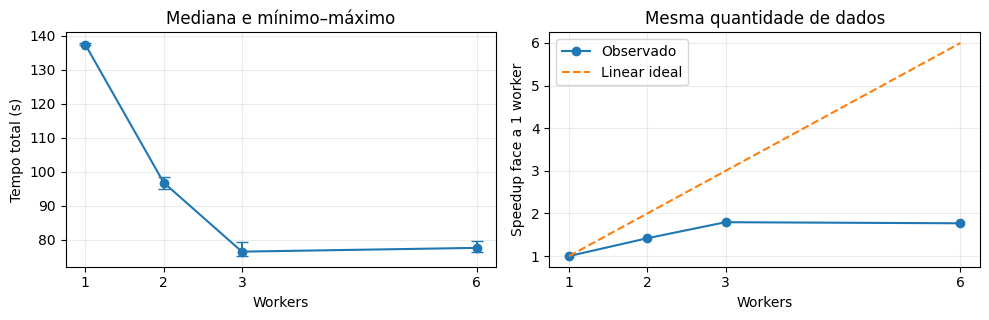

In [32]:
# Guardar uma figura pequena que também pode entrar no relatório.
import matplotlib.pyplot as plt
scale_workers=scale_summary.index.to_numpy()
scale_medians=scale_summary["median_total_s"].to_numpy()
scale_errors=[
    scale_medians-scale_summary["min_total_s"].to_numpy(),
    scale_summary["max_total_s"].to_numpy()-scale_medians
]
fig,axes=plt.subplots(1,2,figsize=(10,3.3))
axes[0].errorbar(scale_workers,scale_medians,yerr=scale_errors,marker="o",capsize=4)
axes[0].set(xlabel="Workers",ylabel="Tempo total (s)",title="Mediana e mínimo–máximo")
axes[1].plot(scale_workers,scale_summary["speedup_vs_1w"],marker="o",label="Observado")
axes[1].plot(scale_workers,scale_workers,"--",label="Linear ideal")
axes[1].set(xlabel="Workers",ylabel="Speedup face a 1 worker",title="Mesma quantidade de dados")
for axis in axes:
    axis.set_xticks(scale_workers)
    axis.grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
fig.savefig(results_folder/"escala_tempos_speedup.png",dpi=160,bbox_inches="tight")
plt.show()


In [33]:
# Ver onde o tempo mudou; o total é medido à parte.
scale_blocks=[]
for folder in sorted(results_folder.glob("escala_*w_cache_*")):
    info=json.loads((folder/"run_info.json").read_text(encoding="utf-8"))
    cluster=json.loads((folder/"cluster_info.json").read_text(encoding="utf-8-sig"))
    scale_blocks.append({"workers":cluster["workers"],**info["timings_s"]})
pd.DataFrame(scale_blocks).groupby("workers").median().round(2)


,M1_stats,M1_clean_count,M2_write,M3_write,O1_rates,O2_routes_write,O2_reversal_write,O2_top
workers,,,,,,,,
1,15.82,50.59,16.58,13.49,10.52,5.56,5.17,8.79
2,9.79,27.32,14.05,10.50,7.69,5.12,4.31,6.41
3,8.37,18.41,11.38,8.81,5.13,4.37,3.41,4.77
6,9.37,15.51,9.41,7.99,7.30,5.68,3.96,4.19


Contagem dos ficheiros Parquet produzidos. Mesmo com o mesmo resultado lógico, os recursos e as decisões automáticas de particionamento podem mudar a organização física das saídas. O número de ficheiros é uma evidência adicional, não uma explicação isolada de todo o tempo.


In [34]:
scale_files=pd.read_json(results_folder/"escala_ficheiros_escritos.json")
scale_files.sort_values(["workers","run"])


,run,workers,m2_demand,m3_zone_month,o2_route_month,o2_q1_q3_reversal
0,escala_1w_cache_01,1,12,6,2,2
1,escala_1w_cache_02,1,12,6,2,2
2,escala_1w_cache_03,1,12,6,2,2
3,escala_2w_cache_01,2,18,6,4,4
4,escala_2w_cache_02,2,18,6,4,4
5,escala_2w_cache_03,2,18,6,4,4
6,escala_3w_cache_01,3,18,6,6,5
7,escala_3w_cache_02,3,18,6,6,5
8,escala_3w_cache_03,3,18,6,6,5
9,escala_6w_cache_01,6,18,6,8,6


### 12.4 Resultados preservados

Depois das medições, comparamos as sete tabelas de cada uma das doze corridas com `baseline_com_cache_01`. Verificamos chaves, colunas e ausência de chaves repetidas. Contagens, decimais, rankings e flags são exatos; floats usam tolerância absoluta `1e-9` e relativa `1e-12`. Os quatro diretórios Parquet de cada corrida têm `_SUCCESS`.


In [35]:
scale_checks=pd.concat([
    pd.read_json(results_folder/f"comparacao_escala_{w}w_resultados.json")
    for w in [1,2,3,6]
],ignore_index=True)
assert len(scale_checks)==84 and scale_checks["differences"].eq(0).all()
scale_checks.groupby("run").agg(tables=("table","count"),differences=("differences","sum"))


,tables,differences
run,,
escala_1w_cache_01,7,0
escala_1w_cache_02,7,0
escala_1w_cache_03,7,0
escala_2w_cache_01,7,0
escala_2w_cache_02,7,0
escala_2w_cache_03,7,0
escala_3w_cache_01,7,0
escala_3w_cache_02,7,0
escala_3w_cache_03,7,0


### 12.5 O que observámos

Medianas da pipeline: 1 worker → 137.384 s; 2 → 96.854 s; 3 → 76.546 s; 6 → 77.653 s. A menor mediana foi com 3 workers. Os speedups face a um worker foram: 2 → 1.42×; 3 → 1.79×; 6 → 1.77×. Os resultados finais coincidiram nas 84 comparações.

Mantemos três workers para as próximas experiências: nesta amostra teve a menor mediana e seis não apresentou um ganho de tempo que compensasse duplicar os recursos anunciados. As faixas dos tempos de três e seis sobrepõem-se, por isso não afirmamos que três seja sempre mais rápido. Esta é uma escolha prática para o ambiente testado, não o número ótimo para qualquer conjunto de dados.

Não atribuímos todo o ganho ao CPU: a memória total também aumentou, o que pode ajudar a cache. As métricas de spill de execução não dizem, por si só, se a cache ficou toda em RAM. Para discutir as diferenças, usamos também os tempos por módulo, tarefas e shuffle, sem tratar `input_bytes` como prova isolada de leitura física de disco.

São containers no mesmo PC, com o mesmo disco e sistema operativo. Não medimos uma rede entre máquinas físicas nem isolámos o efeito de aquecimento, cache do SO ou outros processos. A ordem cíclica reduz algumas diferenças temporais entre configurações, mas não é aleatória. Estes resultados descrevem os recursos e os dados testados, não garantem escala linear noutro ambiente. O ambiente foi reposto em três workers no fim.


## 13. Dimensão dos dados — anos e amostragem

**Comparações concluídas:** por anos (complementar, secções 13.1–13.5) e por amostra de 10% contra 100% (pedida no enunciado, secção 13.6). As medições da amostra percorrem a pipeline completa.

Hipótese: aumentar a quantidade de dados aumenta o tempo, mas os custos fixos de coordenação e dos módulos podem fazer variar o tempo por milhão de viagens.

O aluno escolheu 2023, 2023+2024 e 2022+2023+2024. Usámos os 12 meses de cada ano, a 100%, ou seja, 12, 24 e 36 ficheiros. Ao contrário de uma amostra aplicada depois da leitura, aqui muda o conjunto de ficheiros efetivamente aberto pela pipeline.

Mantivemos três workers/seis slots Spark, 1536 MiB por executor, cache, broadcast, O1 por groupBy, AQE e 200 partições iniciais de shuffle. Não alterámos o algoritmo. As três corridas de dois anos são `escala_3w_cache_*`, reutilizadas da experiência anterior. As novas corridas são `dimensao_2023_cache_*` e `dimensao_2022_2023_2024_cache_*`.

A ordem real foi: medições anteriores com dois anos; três corridas com 2023; três com os três anos. Não alternámos as dimensões nem controlámos a cache de ficheiros do SO. Os anos também têm distribuições e qualidade diferentes: não são cópias do mesmo conjunto de viagens.

### 13.1 Ficheiros e contagens reais

Conferimos os nomes dos 12 meses de cada ano e somámos as linhas dos metadados Parquet, sem depender das contagens produzidas pela pipeline. O tamanho abaixo é o dos ficheiros Parquet completos; não equivale aos bytes físicos lidos pelo Spark, que seleciona apenas algumas colunas.


In [36]:
dimension_validation=json.loads((results_folder/"verificacao_dimensao.json").read_text(encoding="utf-8"))
dimension_inventory=pd.DataFrame(dimension_validation["inventory"])
dimension_inventory["source_GiB"]=dimension_inventory["bytes"]/1024**3
dimension_inventory[["year","files","raw_rows","source_GiB"]].round(3)


,year,files,raw_rows,source_GiB
0,2022,12,39656098,0.573
1,2023,12,38310226,0.592
2,2024,12,41169720,0.645


### 13.2 Comandos e tempos individuais

Exemplo para 2023:

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 --fraction 1.0 --shuffle-partitions 200 --output /project/data/experiencias/dimensao_2023_cache_01
```

Para três anos, usar `--years 2022 2023 2024` e a pasta `dimensao_2022_2023_2024_cache_01`. As repetições seguintes usam `_02` e `_03`. O arranque Spark fica fora do total; leitura, limpeza, preenchimento da cache e escritas estão incluídos.


In [37]:
dimension_cases={
    "2023":([2023],"dimensao_2023_cache"),
    "2023+2024":([2023,2024],"escala_3w_cache"),
    "2022+2023+2024":([2022,2023,2024],"dimensao_2022_2023_2024_cache")
}
dimension_runs=[]
for period,(years,prefix) in dimension_cases.items():
    raw_rows=sum(x["raw_rows"] for x in dimension_validation["inventory"] if x["year"] in years)
    source_bytes=sum(x["bytes"] for x in dimension_validation["inventory"] if x["year"] in years)
    for number in [1,2,3]:
        folder=results_folder/f"{prefix}_{number:02d}"
        info=json.loads((folder/"run_info.json").read_text(encoding="utf-8"))
        metrics=json.loads((folder/"profile_metrics.json").read_text(encoding="utf-8"))
        assert info["years"]==years and info["parallelism"]==6
        dimension_runs.append({
            "period":period,"run":folder.name,"files":info["files"],"raw_rows":raw_rows,
            "valid_rows":info["clean_rows"],"source_GiB":source_bytes/1024**3,
            "total_s":info["total_s"],"stages":metrics["num_stages"],"tasks":metrics["num_tasks"],
            "executor_cpu_s":metrics["executor_cpu_time_ms"]/1000,
            "shuffle_write_MiB":metrics["shuffle_write_bytes"]/1024**2,
            "disk_spill_MiB":metrics["disk_spilled_bytes"]/1024**2
        })
dimension_table=pd.DataFrame(dimension_runs)
assert len(dimension_table)==9
dimension_table.round(3)


,period,run,files,raw_rows,valid_rows,source_GiB,total_s,stages,tasks,executor_cpu_s,shuffle_write_MiB,disk_spill_MiB
0,2023,dimensao_2023_cache_01,12,38310226,35078287,0.592,48.469,123,2746,102.236,55.532,0.0
1,2023,dimensao_2023_cache_02,12,38310226,35078287,0.592,45.932,130,2834,101.571,55.542,0.0
2,2023,dimensao_2023_cache_03,12,38310226,35078287,0.592,44.509,130,2834,101.694,55.535,0.0
3,2023+2024,escala_3w_cache_01,24,79479946,70353039,1.237,76.546,142,5469,228.298,129.630,0.0
4,2023+2024,escala_3w_cache_02,24,79479946,70353039,1.237,75.244,135,5309,231.363,129.790,0.0
5,2023+2024,escala_3w_cache_03,24,79479946,70353039,1.237,79.306,135,5309,231.687,129.733,0.0
6,2022+2023+2024,dimensao_2022_2023_2024_cache_01,36,119136044,106562994,1.810,100.944,154,8078,322.186,164.575,0.0
7,2022+2023+2024,dimensao_2022_2023_2024_cache_02,36,119136044,106562994,1.810,101.328,147,7846,336.449,164.513,0.0
8,2022+2023+2024,dimensao_2022_2023_2024_cache_03,36,119136044,106562994,1.810,101.436,154,8078,336.708,164.570,0.0


### 13.3 Crescimento do tempo e débito

Aqui os recursos são fixos e a quantidade de dados muda. Não chamamos speedup à comparação de anos diferentes. Mostramos a razão do tempo face a 2023 e o débito em milhões de linhas brutas e de viagens válidas por segundo, usando a mediana do tempo total.


In [38]:
dimension_summary=dimension_table.groupby("period",sort=False).agg(
    repetitions=("total_s","count"),files=("files","first"),raw_rows=("raw_rows","first"),
    valid_rows=("valid_rows","first"),source_GiB=("source_GiB","first"),
    mean_total_s=("total_s","mean"),median_total_s=("total_s","median"),
    min_total_s=("total_s","min"),max_total_s=("total_s","max"),
    median_tasks=("tasks","median"),median_shuffle_write_MiB=("shuffle_write_MiB","median"),
    median_disk_spill_MiB=("disk_spill_MiB","median")
)
assert dimension_summary["repetitions"].eq(3).all()
dimension_summary["time_ratio_vs_2023"]=dimension_summary["median_total_s"]/dimension_summary.loc["2023","median_total_s"]
dimension_summary["valid_row_ratio_vs_2023"]=dimension_summary["valid_rows"]/dimension_summary.loc["2023","valid_rows"]
dimension_summary["raw_Mrows_per_s"]=dimension_summary["raw_rows"]/1e6/dimension_summary["median_total_s"]
dimension_summary["valid_Mtrips_per_s"]=dimension_summary["valid_rows"]/1e6/dimension_summary["median_total_s"]
dimension_summary.round(3)


,repetitions,files,raw_rows,valid_rows,source_GiB,mean_total_s,median_total_s,min_total_s,max_total_s,median_tasks,median_shuffle_write_MiB,median_disk_spill_MiB,time_ratio_vs_2023,valid_row_ratio_vs_2023,raw_Mrows_per_s,valid_Mtrips_per_s
period,,,,,,,,,,,,,,,,
2023,3,12,38310226,35078287,0.592,46.303,45.932,44.509,48.469,2834.0,55.535,0.0,1.000,1.000,0.834,0.764
2023+2024,3,24,79479946,70353039,1.237,77.032,76.546,75.244,79.306,5309.0,129.733,0.0,1.667,2.006,1.038,0.919
2022+2023+2024,3,36,119136044,106562994,1.810,101.236,101.328,100.944,101.436,8078.0,164.570,0.0,2.206,3.038,1.176,1.052


O gráfico usa o número de linhas brutas real, obtido dos metadados. As barras de erro mostram mínimo–máximo das três corridas, não intervalos de confiança.


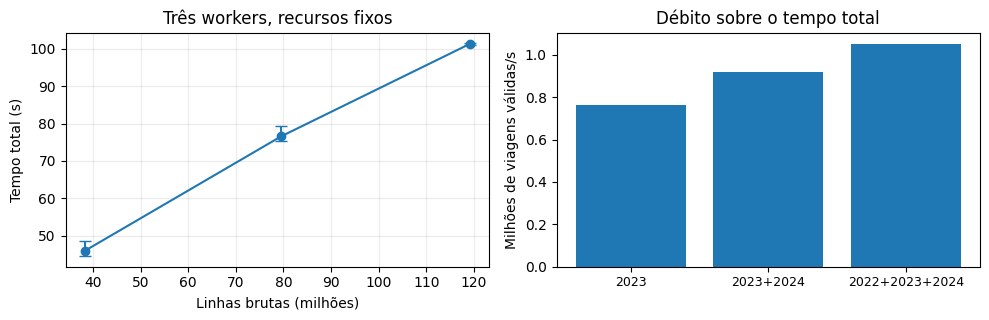

In [39]:
import matplotlib.pyplot as plt
dimension_medians=dimension_summary["median_total_s"].to_numpy()
dimension_errors=[dimension_medians-dimension_summary["min_total_s"].to_numpy(),
                  dimension_summary["max_total_s"].to_numpy()-dimension_medians]
fig,axes=plt.subplots(1,2,figsize=(10,3.3))
axes[0].errorbar(dimension_summary["raw_rows"]/1e6,dimension_medians,
                yerr=dimension_errors,marker="o",capsize=4)
axes[0].set(xlabel="Linhas brutas (milhões)",ylabel="Tempo total (s)",title="Três workers, recursos fixos")
axes[0].grid(alpha=0.25)
axes[1].bar(dimension_summary.index,dimension_summary["valid_Mtrips_per_s"])
axes[1].set(ylabel="Milhões de viagens válidas/s",title="Débito sobre o tempo total")
axes[1].tick_params(axis="x",labelsize=9)
fig.tight_layout()
fig.savefig(results_folder/"dimensao_tempos_debito.png",dpi=160,bbox_inches="tight")
plt.show()


In [40]:
# Comparar o tempo dos módulos entre as três dimensões.
dimension_blocks=[]
for period,(years,prefix) in dimension_cases.items():
    for number in [1,2,3]:
        info=json.loads((results_folder/f"{prefix}_{number:02d}/run_info.json").read_text(encoding="utf-8"))
        dimension_blocks.append({"period":period,**info["timings_s"]})
pd.DataFrame(dimension_blocks).groupby("period",sort=False).median().round(2)


,M1_stats,M1_clean_count,M2_write,M3_write,O1_rates,O2_routes_write,O2_reversal_write,O2_top
period,,,,,,,,
2023,5.52,8.52,5.73,6.11,4.12,2.73,1.98,2.52
2023+2024,8.37,18.41,11.38,8.81,5.13,4.37,3.41,4.77
2022+2023+2024,11.05,27.69,14.84,10.29,7.23,5.08,4.40,6.14


### 13.4 Validação adequada a cada período

As saídas de períodos diferentes não têm de ser iguais. Por exemplo, as médias de M2, a referência estatística de O1 e o top global de O2 podem mudar ao acrescentar viagens.

Na primeira corrida de cada dimensão, conferimos os totais brutos de M1 com os metadados Parquet e verificamos contagens e limites em M1–O2. M2, M3, O1 e as rotas de O2 têm de conservar a contagem das viagens válidas. M3 deve ter 263 × 12 × número de anos linhas; as shares das rotas somam um por origem/ano/mês.

Comparamos depois as sete tabelas das outras duas repetições com a primeira do mesmo período: 42 comparações. Contagens, decimais, rankings e flags são exatos; floats usam tolerância absoluta `1e-9` e relativa `1e-12`.

Fizemos ainda 15 comparações entre períodos sobre resultados anuais comparáveis: M1, rotas e inversões de O2 nos anos comuns; estatísticas mensais de M3; e janelas de M3 apenas onde existe o mesmo histórico. Acrescentar 2022 muda legitimamente o histórico de janeiro–março de 2023. Nessa comparação, as linhas completas de M3 só são confrontadas a partir de abril de 2023. As estatísticas mensais sem janelas continuam comparáveis em todos os meses comuns.

As escritas Parquet têm `_SUCCESS`, e as chaves/colunas e ausência de chaves repetidas são conferidas nas comparações. O script é `experiencias/verificar_dimensao.py`; o resumo fica em `verificacao_dimensao.json`.


In [41]:
dimension_invariants=pd.DataFrame(dimension_validation["invariants"])
dimension_checks=pd.DataFrame(dimension_validation["comparisons"])
assert dimension_invariants["passed"].all()
assert len(dimension_checks)==57 and dimension_checks["differences"].eq(0).all()
print("Invariantes que passaram:",len(dimension_invariants))
print("Comparações de tabelas sem diferenças:",len(dimension_checks))
dimension_checks.groupby("comparison").agg(tables=("table","count"),differences=("differences","sum"))


Invariantes que passaram: 60
Comparações de tabelas sem diferenças: 57


,tables,differences
comparison,,
2022+2023+2024: repeticao 2 vs 1,7,0
2022+2023+2024: repeticao 3 vs 1,7,0
2023 vs 2022+2023+2024: anos comuns,3,0
2023 vs 2022+2023+2024: anos comuns (M3 historico comparavel),1,0
2023 vs 2022+2023+2024: anos comuns (M3 sem janelas),1,0
2023 vs 2023+2024: anos comuns,3,0
2023 vs 2023+2024: anos comuns (M3 historico comparavel),1,0
2023 vs 2023+2024: anos comuns (M3 sem janelas),1,0
2023+2024 vs 2022+2023+2024: anos comuns,3,0


### 13.5 Conclusão

Medianas: 2023 → 45.932 s; 2023+2024 → 76.546 s; três anos → 101.328 s. As contagens válidas foram 35,078,287, 70,353,039 e 106,562,994, respetivamente.

Entre um e três anos, o número de viagens válidas aumentou 3.04× e o tempo mediano 2.21×. O tempo por viagem não foi constante nestes períodos. Os tempos por módulo e o trabalho fixo ajudam a enquadrar o resultado, mas não isolámos uma causa única. Os anos têm distribuições diferentes e o AQE também pode mudar o plano.

Esta experiência aumenta o conjunto de dados com recursos fixos; não é weak scaling, que aumentaria também os recursos proporcionalmente. Três repetições e três períodos reais não permitem garantir uma lei de crescimento ou extrapolar para dados muito maiores. O conjunto principal do projeto mantém-se 2023+2024; 2022 foi acrescentado apenas nesta análise de dimensão, sem alterar o código da pipeline.


### 13.6 Amostra de 10% contra 100% — comparação pedida no enunciado

Esta medição percorre M1, M2, M3, O1 e O2, incluindo as escritas. Não é apenas o tempo dos testes do notebook de validação. Usámos os mesmos 24 ficheiros de 2023/2024, três workers/seis slots, 1536 MiB por executor, cache, broadcast, O1 por groupBy, AQE e 200 partições iniciais de shuffle.

Mudámos só `--fraction 0.1`. O código usa a seed 42 na amostragem. A amostra é aleatória e o número de linhas observado não tem de ser exatamente 10%. O preenchimento da cache e as escritas entram no total; o arranque Spark e a exportação das métricas ficam de fora.

As três corridas com 100% são `escala_3w_cache_*`, feitas anteriormente. Fizemos três aplicações novas com 10%, nas pastas `amostra_10pct_cache_*`. A ordem não foi alternada e a cache de ficheiros do SO não foi controlada.

Comando da primeira repetição (usar `_02` e `_03` nas seguintes):

```powershell
docker compose -f compose.project.yml exec -T jupyter /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.driver.host=jupyter --conf spark.driver.bindAddress=0.0.0.0 --executor-memory 1536m /project/projeto1.py --data /project/data/raw --years 2023 2024 --fraction 0.1 --shuffle-partitions 200 --output /project/data/experiencias/amostra_10pct_cache_01
```


In [42]:
# Ler as seis medições completas, sem voltar a executar Spark.
sample_validation=json.loads((results_folder/"verificacao_amostra_10pct.json").read_text(encoding="utf-8"))
sample_runs=[]
for fraction,prefix in [(0.1,"amostra_10pct_cache"),(1.0,"escala_3w_cache")]:
    for number in [1,2,3]:
        folder=results_folder/f"{prefix}_{number:02d}"
        info=json.loads((folder/"run_info.json").read_text(encoding="utf-8"))
        metrics=json.loads((folder/"profile_metrics.json").read_text(encoding="utf-8"))
        stats=pd.read_csv(folder/"m1_cleaning_stats.csv")
        assert info["fraction"]==fraction and info["parallelism"]==6
        sample_runs.append({
            "run":folder.name,"fraction":fraction,"files":info["files"],
            "selected_rows_before_cleaning":int(stats["total"].sum()),
            "valid_rows":info["clean_rows"],"total_s":info["total_s"],
            "tasks":metrics["num_tasks"],"stages":metrics["num_stages"],
            "shuffle_write_MiB":metrics["shuffle_write_bytes"]/1024**2,
            "disk_spill_MiB":metrics["disk_spilled_bytes"]/1024**2
        })
sample_table=pd.DataFrame(sample_runs)
assert len(sample_table)==6 and sample_table["files"].eq(24).all()
sample_table.round(3)


,run,fraction,files,selected_rows_before_cleaning,valid_rows,total_s,tasks,stages,shuffle_write_MiB,disk_spill_MiB
0,amostra_10pct_cache_01,0.1,24,7947434,7036182,46.842,5282,135,64.314,0.0
1,amostra_10pct_cache_02,0.1,24,7947434,7036182,44.523,5442,142,64.284,0.0
2,amostra_10pct_cache_03,0.1,24,7947434,7036182,45.802,5282,135,64.263,0.0
3,escala_3w_cache_01,1.0,24,79479946,70353039,76.546,5469,142,129.630,0.0
4,escala_3w_cache_02,1.0,24,79479946,70353039,75.244,5309,135,129.790,0.0
5,escala_3w_cache_03,1.0,24,79479946,70353039,79.306,5309,135,129.733,0.0


#### 13.6.1 Medianas e crescimento do tempo

As linhas de M1 são as selecionadas antes da limpeza; não equivalem ao número de linhas fisicamente lidas do disco. As barras de erro mostram mínimo–máximo das três corridas, não intervalos de confiança.


,repetitions,selected_rows,valid_rows,mean_s,median_s,min_s,max_s,median_tasks,median_shuffle_write_MiB,median_disk_spill_MiB,time_ratio_vs_10pct,valid_row_ratio_vs_10pct
fraction,,,,,,,,,,,,
0.1,3,7947434,7036182,45.722,45.802,44.523,46.842,5282.0,64.284,0.0,1.000,1.000
1.0,3,79479946,70353039,77.032,76.546,75.244,79.306,5309.0,129.733,0.0,1.671,9.999


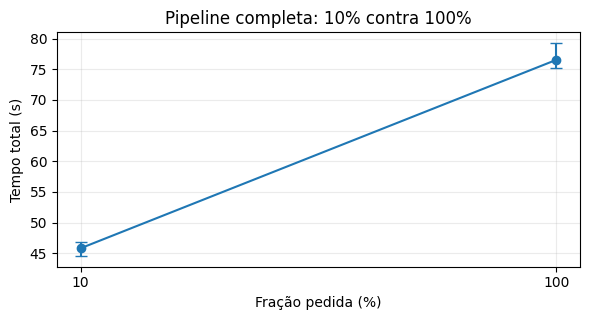

In [43]:
sample_summary=sample_table.groupby("fraction").agg(
    repetitions=("total_s","count"),selected_rows=("selected_rows_before_cleaning","first"),
    valid_rows=("valid_rows","first"),mean_s=("total_s","mean"),median_s=("total_s","median"),
    min_s=("total_s","min"),max_s=("total_s","max"),median_tasks=("tasks","median"),
    median_shuffle_write_MiB=("shuffle_write_MiB","median"),
    median_disk_spill_MiB=("disk_spill_MiB","median")
)
assert sample_summary["repetitions"].eq(3).all()
sample_summary["time_ratio_vs_10pct"]=sample_summary["median_s"]/sample_summary.loc[0.1,"median_s"]
sample_summary["valid_row_ratio_vs_10pct"]=sample_summary["valid_rows"]/sample_summary.loc[0.1,"valid_rows"]
display(sample_summary.round(3))

import matplotlib.pyplot as plt
fractions=sample_summary.index.to_numpy()*100
times=sample_summary["median_s"].to_numpy()
errors=[times-sample_summary["min_s"].to_numpy(),sample_summary["max_s"].to_numpy()-times]
fig,ax=plt.subplots(figsize=(6,3.3))
ax.errorbar(fractions,times,yerr=errors,marker="o",capsize=4)
ax.set(xlabel="Fração pedida (%)",ylabel="Tempo total (s)",title="Pipeline completa: 10% contra 100%")
ax.set_xticks([10,100])
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(results_folder/"amostra_10_100_tempos.png",dpi=160,bbox_inches="tight")
plt.show()


#### 13.6.2 Conferir os resultados da amostra

O script `experiencias/verificar_amostra.py` confere a configuração, os totais de M1, a conservação das contagens em M2/M3/O1/O2, a grelha de M3, os limites das taxas e as participações das rotas.

Compara as sete tabelas das repetições 2 e 3 com a primeira: 14 comparações. Neste PC, compara ainda M2, M3 e as três tabelas de O2 com as saídas da validação anterior a 10%: mais cinco comparações. Estas saídas antigas são opcionais para reproduzir a verificação noutro PC; não são necessárias para repetir a medição. As escritas Parquet têm `_SUCCESS` e as chaves não se repetem.

Contagens, decimais, rankings e flags são exatos. Para floats, usamos tolerância absoluta `1e-9` e relativa `1e-12`. Não exigimos igualdade entre as tabelas de 10% e 100%, porque representam conjuntos de viagens diferentes.


In [44]:
sample_checks=pd.DataFrame(sample_validation["comparisons"])
sample_invariants=pd.DataFrame(sample_validation["invariants"])
assert sample_invariants["passed"].all() and sample_checks["differences"].eq(0).all()
print("Verificações que passaram:",len(sample_invariants))
print("Comparações sem diferenças:",len(sample_checks))
print("Fração observada das linhas antes da limpeza:",round(sample_validation["observed_raw_fraction"],6))
print("Fração observada das viagens válidas:",round(sample_validation["observed_valid_fraction"],6))
sample_checks.groupby("comparison").agg(tables=("table","count"),differences=("differences","sum"))


Verificações que passaram: 24
Comparações sem diferenças: 19
Fração observada das linhas antes da limpeza: 0.099993
Fração observada das viagens válidas: 0.100012


,tables,differences
comparison,,
repeticao 2 vs 1,7,0
repeticao 3 vs 1,7,0
vs validacao anterior a 10%,5,0


#### 13.6.3 Conclusão

Medianas: 10% → 45.802 s; 100% → 76.546 s. As viagens válidas passaram de 7,036,182 para 70,353,039: cerca de 10.00 vezes mais, com um tempo 1.67 vezes maior. O crescimento observado do tempo foi sublinear face ao número de viagens que seguiram após a limpeza.

Isto não significa que ler dez vezes mais dados seja quase gratuito. O `sample` é aplicado depois da união dos dados: as duas configurações usam os mesmos 24 ficheiros de entrada. Reduzimos as viagens que seguem para as etapas seguintes, não a lista de ficheiros. M3 mantém também a grelha completa de 6312 combinações zona/mês. Há, portanto, trabalho comum e custos fixos que não ficam dez vezes menores.

A comparação por anos da secção anterior complementa este teste, porque muda efetivamente os ficheiros usados. As diferenças de plano, cache e distribuição dos dados também podem afetar o tempo; não isolámos cada causa. São três repetições por fração, com as medições de 100% anteriores às de 10%, no mesmo PC. Mantemos 100% de 2023+2024 como dados principais do projeto.


## 14. Síntese das decisões

As tabelas abaixo usam as medições guardadas, sem lançar novas corridas. São medianas de três repetições por configuração. Os tempos são da pipeline completa; na linha de O1 mostramos também o bloco O1, identificado à parte.

As comparações foram feitas mudando uma opção de cada vez. Várias reutilizam a mesma referência com cache; não são melhorias sucessivas cujas percentagens se possam somar.

### 14.1 O que escolhemos


In [45]:
from IPython.display import display

decision_summary=pd.DataFrame([
    {"Experiência":"Cache",
     "Evidência":f"Sem cache: {cache_summary.loc[False,'median_s']:.2f} s; com cache: {cache_summary.loc[True,'median_s']:.2f} s.",
     "Decisão":"Ativa; o custo de a preencher entrou na medição."},
    {"Experiência":"O1: janela ou groupBy",
     "Evidência":f"Pipeline: janela {o1_summary.loc['window','median_total_s']:.2f} s; groupBy {o1_summary.loc['groupby','median_total_s']:.2f} s. Bloco O1: {o1_summary.loc['window','median_O1_s']:.2f} → {o1_summary.loc['groupby','median_O1_s']:.2f} s.",
     "Decisão":"groupBy com broadcast das pequenas estatísticas."},
    {"Experiência":"Junções com zonas",
     "Evidência":f"Broadcast: {join_summary.loc['broadcast','median_total_s']:.2f} s; sort-merge: {join_summary.loc['sortmerge','median_total_s']:.2f} s.",
     "Decisão":"Broadcast da tabela de zonas."},
    {"Experiência":"AQE",
     "Evidência":f"Ligado: {aqe_summary.loc[True,'median_total_s']:.2f} s; desligado: {aqe_summary.loc[False,'median_total_s']:.2f} s.",
     "Decisão":"Ligado; M2 mostrou agrupamento de partições no plano final."},
    {"Experiência":"Partições iniciais de shuffle",
     "Evidência":"; ".join(f"{p}: {shuffle_summary.loc[p,'median_total_s']:.2f} s" for p in [12,24,200])+".",
     "Decisão":"Manter 200 com AQE; vantagem de 12 foi pequena e as faixas sobrepõem-se."},
    {"Experiência":"Workers",
     "Evidência":"; ".join(f"{w}: {scale_summary.loc[w,'median_total_s']:.2f} s" for w in [1,2,3,6])+".",
     "Decisão":"Manter 3; 6 não mostrou ganho que justificasse duplicar os recursos anunciados."},
    {"Experiência":"Dimensão dos dados",
     "Evidência":"; ".join(f"{p}: {dimension_summary.loc[p,'median_total_s']:.2f} s" for p in dimension_cases)+".",
     "Decisão":"Projeto com 2023+2024; 2022 foi usado na análise de dimensão."},
    {"Experiência":"Amostra de 10% contra 100%",
     "Evidência":f"10%: {sample_summary.loc[0.1,'median_s']:.2f} s; 100%: {sample_summary.loc[1.0,'median_s']:.2f} s.",
     "Decisão":"Comparação pedida no enunciado concluída; os mesmos 24 ficheiros são usados nas duas frações."}
])
with pd.option_context("display.max_colwidth",None):
    display(decision_summary)


,Experiência,Evidência,Decisão
0,Cache,Sem cache: 101.27 s; com cache: 76.86 s.,Ativa; o custo de a preencher entrou na medição.
1,O1: janela ou groupBy,Pipeline: janela 83.30 s; groupBy 76.86 s. Bloco O1: 12.68 → 5.20 s.,groupBy com broadcast das pequenas estatísticas.
2,Junções com zonas,Broadcast: 76.86 s; sort-merge: 95.89 s.,Broadcast da tabela de zonas.
3,AQE,Ligado: 76.86 s; desligado: 333.60 s.,Ligado; M2 mostrou agrupamento de partições no plano final.
4,Partições iniciais de shuffle,12: 75.71 s; 24: 76.22 s; 200: 76.86 s.,Manter 200 com AQE; vantagem de 12 foi pequena e as faixas sobrepõem-se.
5,Workers,1: 137.38 s; 2: 96.85 s; 3: 76.55 s; 6: 77.65 s.,Manter 3; 6 não mostrou ganho que justificasse duplicar os recursos anunciados.
6,Dimensão dos dados,2023: 45.93 s; 2023+2024: 76.55 s; 2022+2023+2024: 101.33 s.,Projeto com 2023+2024; 2022 foi usado na análise de dimensão.
7,Amostra de 10% contra 100%,10%: 45.80 s; 100%: 76.55 s.,Comparação pedida no enunciado concluída; os mesmos 24 ficheiros são usados nas duas frações.


### 14.2 Gráfico e tabela das otimizações

Resumo quantitativo para a tabela de impacto do relatório. As quatro linhas comparam alternativas testadas com a configuração escolhida. Não representam quatro alterações sucessivas: a alternativa escolhida reutiliza as mesmas três corridas `baseline_com_cache_*`.

Todos os valores são do **tempo da pipeline completa**, com 100% de 2023+2024, três workers e 1536 MiB por executor. Em O1, o ganho do bloco isolado está na secção 8; não é misturado com o ganho global deste gráfico. As barras de erro mostram mínimo–máximo das três corridas, não intervalos de confiança.

A redução é `100 × (1 − mediana escolhida / mediana alternativa)`. Não somar as quatro percentagens nem apresentar as alternativas já existentes no código como alterações implementadas depois destas medições.


In [46]:
# Preparar a tabela a partir dos JSON originais de cada corrida.
optimization_specs=[
    ("Cache","Sem cache → cache","baseline_sem_cache","cache"),
    ("O1","Janela → groupBy","o1_window_cache","o1_method"),
    ("Joins das zonas","Sort-merge → broadcast","zonas_sortmerge_cache","broadcast"),
    ("AQE","Desligado → ligado","aqe_desligado_cache","aqe")
]
selected_prefix="baseline_com_cache"
selected_infos=[json.loads((results_folder/f"{selected_prefix}_{n:02d}/run_info.json").read_text(encoding="utf-8")) for n in [1,2,3]]
selected_times=pd.Series([info["total_s"] for info in selected_infos])
optimization_records=[]
fixed_keys=["years","fraction","files","modules","parallelism","spark_version",
            "executor_memory","shuffle_partitions","cache","broadcast","aqe","o1_method"]
for name,change,prefix,changed_key in optimization_specs:
    alternative_infos=[json.loads((results_folder/f"{prefix}_{n:02d}/run_info.json").read_text(encoding="utf-8")) for n in [1,2,3]]
    for info in alternative_infos:
        assert all(info[key]==selected_infos[0][key] for key in fixed_keys if key!=changed_key)
        assert info["clean_rows"]==selected_infos[0]["clean_rows"]
    alternative_times=pd.Series([info["total_s"] for info in alternative_infos])
    optimization_records.append({
        "experiment":name,"change":change,"alternative_prefix":prefix,"selected_prefix":selected_prefix,
        "alternative_times_s":alternative_times.tolist(),"selected_times_s":selected_times.tolist(),
        "alternative_median_s":float(alternative_times.median()),
        "alternative_min_s":float(alternative_times.min()),"alternative_max_s":float(alternative_times.max()),
        "selected_median_s":float(selected_times.median()),
        "selected_min_s":float(selected_times.min()),"selected_max_s":float(selected_times.max()),
        "reduction_pct":float(100*(1-selected_times.median()/alternative_times.median()))
    })
optimization_data=pd.DataFrame(optimization_records)
optimization_table=optimization_data[["experiment","change","alternative_median_s","selected_median_s","reduction_pct"]].rename(columns={
    "experiment":"Experiência","change":"Comparação",
    "alternative_median_s":"Alternativa (s)","selected_median_s":"Escolha (s)","reduction_pct":"Redução (%)"
})
optimization_table.to_csv(results_folder/"otimizacoes_tabela.csv",index=False,float_format="%.3f")
(results_folder/"otimizacoes_resumo.json").write_text(json.dumps(optimization_records,ensure_ascii=False,indent=2),encoding="utf-8")
display(optimization_table.round({"Alternativa (s)":2,"Escolha (s)":2,"Redução (%)":1}))


,Experiência,Comparação,Alternativa (s),Escolha (s),Redução (%)
0,Cache,Sem cache → cache,101.27,76.86,24.1
1,O1,Janela → groupBy,83.30,76.86,7.7
2,Joins das zonas,Sort-merge → broadcast,95.89,76.86,19.8
3,AQE,Desligado → ligado,333.60,76.86,77.0


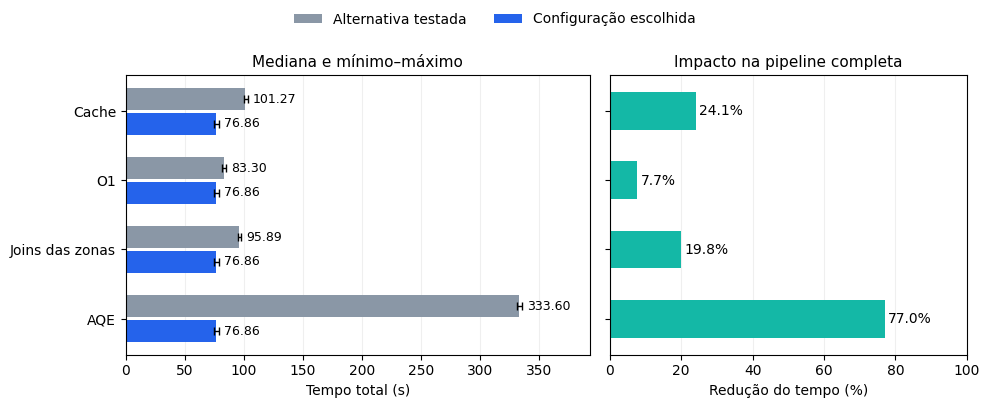

In [47]:
# Comparar tempos e reduções, mantendo a escala dos tempos a começar em zero.
import numpy as np
import matplotlib.pyplot as plt

positions=np.arange(len(optimization_data))
alternative=optimization_data["alternative_median_s"].to_numpy()
selected=optimization_data["selected_median_s"].to_numpy()
alternative_errors=[alternative-optimization_data["alternative_min_s"].to_numpy(),
                    optimization_data["alternative_max_s"].to_numpy()-alternative]
selected_errors=[selected-optimization_data["selected_min_s"].to_numpy(),
                 optimization_data["selected_max_s"].to_numpy()-selected]
with plt.rc_context({"font.size":10,"axes.titlesize":11,"axes.labelsize":10}):
    fig,axes=plt.subplots(1,2,figsize=(10,4.1),sharey=True,gridspec_kw={"width_ratios":[1.3,1]})
    axes[0].barh(positions-0.18,alternative,height=0.32,xerr=alternative_errors,capsize=3,
                 color="#8A97A6",label="Alternativa testada",error_kw={"elinewidth":1})
    axes[0].barh(positions+0.18,selected,height=0.32,xerr=selected_errors,capsize=3,
                 color="#2563EB",label="Configuração escolhida",error_kw={"elinewidth":1})
    for i,row in optimization_data.iterrows():
        axes[0].text(row["alternative_max_s"]+4,i-0.18,f"{row['alternative_median_s']:.2f}",va="center",fontsize=9)
        axes[0].text(row["selected_max_s"]+4,i+0.18,f"{row['selected_median_s']:.2f}",va="center",fontsize=9)
    axes[0].set_yticks(positions,optimization_data["experiment"])
    axes[0].invert_yaxis()
    axes[0].set(xlabel="Tempo total (s)",title="Mediana e mínimo–máximo",xlim=(0,float(optimization_data["alternative_max_s"].max())*1.17))
    axes[1].barh(positions,optimization_data["reduction_pct"],height=0.55,color="#14B8A6")
    for i,value in enumerate(optimization_data["reduction_pct"]):
        axes[1].text(value+1,i,f"{value:.1f}%",va="center",fontsize=10)
    axes[1].set(xlabel="Redução do tempo (%)",title="Impacto na pipeline completa",xlim=(0,100))
    axes[1].tick_params(axis="y",labelleft=False)
    for axis in axes:
        axis.grid(axis="x",alpha=0.2)
        axis.set_axisbelow(True)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="upper center",ncol=2,frameon=False)
    fig.tight_layout(rect=(0,0,1,0.91))
    fig.savefig(results_folder/"otimizacoes_tempos.png",dpi=300,bbox_inches="tight")
    plt.show()


### 14.3 Configuração escolhida e limites

Mantemos **2023+2024, três workers de dois cores, 1536 MiB por executor, cache, broadcast das zonas, O1 por groupBy, AQE ligado e 200 partições iniciais de shuffle**.

Os resultados das variantes foram conferidos nas tabelas das experiências e nos notebooks de validação. Nos testes com períodos diferentes, comparamos apenas resultados logicamente comparáveis, respeitando o histórico das janelas de M3.

- Três repetições por opção não garantem uma vantagem universal. Mostramos média, mediana e os tempos individuais.
- A ordem não foi aleatória; só 12/24 foram alternados e os workers seguiram rondas 1 → 2 → 3 → 6. Não controlámos a cache de ficheiros do SO ou outros processos do PC.
- Todos os containers usam o mesmo PC e disco. Mais workers também aumenta a memória total. Os tempos excluem arranque Spark e preparação dos workers; incluem leitura, materialização da cache e escritas.

A revisão dos ficheiros ficou registada em `experiencias/REVISAO_FINAL.md`. Falta preparar e rever o relatório e o pacote de entrega. A comparação de 10% contra 100% ficou concluída na secção 13.6. A organização não voltou a executar as validações Spark nem alterou os cálculos de `projeto1.py`.

O código inicial já tinha broadcast, AQE e O1 por groupBy. Os testes destas opções comparam alternativas e justificam mantê-las; não documentam uma implementação nova após cada diagnóstico. Não devemos inventar essa sequência no relatório. Não medimos skew por duração de tarefas, overhead de UDF ou ordenação de múltiplos joins.


### 14.4 Elementos a incluir nas quatro páginas do relatório

- Tabela de impacto das otimizações, com base em `otimizacoes_tabela.csv`; o gráfico está em `otimizacoes_tempos.png`.
- Reservar espaço nas **quatro páginas de texto e gráficos para um plano físico anotado**, ou um diagrama simplificado fiel a uma consulta real. Não o deixar apenas no notebook ou na página extra.
- Usar um recorte legível e identificar a origem. Temos os planos de M2 em `planos_zonas` (iniciais) e `planos_aqe` (finais de uma consulta recolhida com `collect()`, numa inspeção separada). Não apresentar esse plano como o plano final da escrita da pipeline inteira.
- Destacar os operadores relevantes, por exemplo `BroadcastHashJoin`, `Exchange` e `AQEShuffleRead coalesced`, ligando a figura ao diagnóstico e às métricas.

Os gráficos de workers e de 10%/100% também estão prontos. A comparação por anos pode ficar como complemento no notebook se o espaço do relatório for curto.


## 15. Arquivo das medições exploratórias

Este arquivo reúne os blocos de desempenho que estavam nos notebooks de validação a 10% e 100%, incluindo o relatório do profiler. O código, as saídas e os números históricos de execução foram preservados em `experiencias/resultados/exploratorias_validacao.json`.

**São medições de uma sessão de validação, com dados já em cache e sem três aplicações novas por alternativa. Não são a baseline nem substituem as comparações controladas das secções anteriores.** Não comparar diretamente os tempos de uma amostra com os da pipeline completa, nem misturar o tempo de um módulo com o total da pipeline.

Expandir um bloco para consultar o código e as saídas originais. A célula seguinte apenas apresenta o arquivo; o código Spark aparece como texto e não é executado.


In [48]:
# Apresentar o código e as saídas históricas sem executar os blocos Spark.
import html
from IPython.display import HTML,display

exploratory_archive=json.loads((results_folder/"exploratorias_validacao.json").read_text(encoding="utf-8"))
def archive_text(value):
    return "".join(value) if isinstance(value,list) else str(value)

for record in exploratory_archive["notebooks"]:
    percent=100*record["fraction"]
    display(HTML(f"<h3>{html.escape(record['notebook'])} — {percent:g}%</h3><p>{html.escape(record['context'])}</p>"))
    for block in record["blocks"]:
        old_cell=block["cell"]
        label=html.escape(block["label"])
        old_source=html.escape(archive_text(old_cell["source"]))
        body=f"<details><summary>{label} — execução histórica {old_cell.get('execution_count')}</summary><pre>{old_source}</pre>"
        for old_output in old_cell.get("outputs",[]):
            data=old_output.get("data",{})
            if old_output["output_type"]=="stream":
                body+="<pre>"+html.escape(archive_text(old_output.get("text","")))+"</pre>"
            elif "text/html" in data:
                body+=archive_text(data["text/html"])
            elif "image/png" in data:
                body+='<img alt="Saída histórica" src="data:image/png;base64,'+archive_text(data["image/png"]).replace("\n","")+'">'
            elif "text/plain" in data:
                body+="<pre>"+html.escape(archive_text(data["text/plain"]))+"</pre>"
        display(HTML(body+"</details>"))


,source_year,total,f_nulls,f_fare,f_distance,f_passengers,f_time,f_location,f_period,f_any,kept
0,2023,3830507,130871,39519,76843,58318,1540,63346,9,322777,3507730
1,2024,4116927,408461,74527,77246,40222,1322,42599,3,588475,3528452


,PULocationID,DOLocationID,pickup_borough,pickup_zone,dropoff_borough,dropoff_zone,total_trips,route_rank,years_with_reversal
0,168,74,Bronx,Mott Haven/Port Morris,Manhattan,East Harlem North,59,1,1
1,168,168,Bronx,Mott Haven/Port Morris,Bronx,Mott Haven/Port Morris,50,2,1
2,247,42,Bronx,West Concourse,Manhattan,Central Harlem North,47,3,2
20,181,181,Brooklyn,Park Slope,Brooklyn,Park Slope,192,1,1
21,255,112,Brooklyn,Williamsburg (North Side),Brooklyn,Greenpoint,184,2,2
22,52,33,Brooklyn,Cobble Hill,Brooklyn,Brooklyn Heights,180,3,1
40,1,1,EWR,Newark Airport,EWR,Newark Airport,168,1,2
41,1,132,EWR,Newark Airport,Queens,JFK Airport,3,2,0
42,1,239,EWR,Newark Airport,Manhattan,Upper West Side South,3,3,0
60,237,236,Manhattan,Upper East Side South,Manhattan,Upper East Side North,51679,1,2


,M2-sortmerge,M2-broadcast,change
metric,,,
wall_time_s,2.07,1.24,-40.1%
num_jobs,4,3,-25.0%
num_stages,9,4,-55.6%
num_tasks,450,292,-35.1%
executor_run_time_ms,9301,5029,-45.9%
executor_cpu_time_ms,8304,4773,-42.5%
input_bytes,360.3MB,360.3MB,+0.0%
output_bytes,0.0B,0.0B,-
shuffle_read_bytes,202.1MB,2.9MB,-98.5%


,O1-window,O1-groupby,change
metric,,,
wall_time_s,2.01,1.59,-20.9%
num_jobs,6,8,+33.3%
num_stages,14,13,-7.1%
num_tasks,753,876,+16.3%
executor_run_time_ms,8219,4465,-45.7%
executor_cpu_time_ms,7821,4145,-47.0%
input_bytes,360.3MB,720.6MB,+100.0%
output_bytes,0.0B,0.0B,-
shuffle_read_bytes,99.8MB,7.3MB,-92.6%


,wall_time_s,num_jobs,num_stages,num_tasks,executor_run_time_ms,executor_cpu_time_ms,input_bytes,output_bytes,shuffle_read_bytes,shuffle_write_bytes,memory_spilled_bytes,disk_spilled_bytes
run,,,,,,,,,,,,
M1-stats,7.41,4,8,580,28941,20247,995.9KB,0.0B,13.8KB,7.0KB,0.0B,0.0B
M1-cache,5.55,3,4,433,26460,19731,361.2MB,0.0B,8.1KB,8.1KB,0.0B,0.0B
M3,1.95,10,26,342,4328,3744,360.3MB,0.0B,3.1MB,3.1MB,0.0B,0.0B
O2,2.22,14,43,1842,6719,6157,720.6MB,0.0B,27.2MB,27.2MB,0.0B,0.0B
M2-sortmerge,2.07,4,9,450,9301,8304,360.3MB,0.0B,202.1MB,202.1MB,0.0B,0.0B
M2-broadcast,1.24,3,4,292,5029,4773,360.3MB,0.0B,2.9MB,2.9MB,0.0B,0.0B
O1-window,2.01,6,14,753,8219,7821,360.3MB,0.0B,99.8MB,99.8MB,0.0B,0.0B
O1-groupby,1.59,8,13,876,4465,4145,720.6MB,0.0B,7.3MB,7.2MB,0.0B,0.0B


,source_year,total,f_nulls,f_fare,f_distance,f_passengers,f_time,f_location,f_period,f_any,kept
0,2023,38310226,1309356,394503,773457,583414,15569,633591,104,3231939,35078287
1,2024,41169720,4091232,748284,776305,401638,13510,425660,56,5894968,35274752


,PULocationID,DOLocationID,pickup_borough,pickup_zone,dropoff_borough,dropoff_zone,total_trips,route_rank,years_with_reversal
0,168,168,Bronx,Mott Haven/Port Morris,Bronx,Mott Haven/Port Morris,546,1,0
1,168,74,Bronx,Mott Haven/Port Morris,Manhattan,East Harlem North,502,2,0
2,247,42,Bronx,West Concourse,Manhattan,Central Harlem North,491,3,1
20,181,181,Brooklyn,Park Slope,Brooklyn,Park Slope,1968,1,0
21,52,33,Brooklyn,Cobble Hill,Brooklyn,Brooklyn Heights,1935,2,2
22,33,33,Brooklyn,Brooklyn Heights,Brooklyn,Brooklyn Heights,1736,3,1
40,1,1,EWR,Newark Airport,EWR,Newark Airport,1649,1,2
41,1,132,EWR,Newark Airport,Queens,JFK Airport,25,2,1
42,1,138,EWR,Newark Airport,Queens,LaGuardia Airport,14,3,0
60,237,236,Manhattan,Upper East Side South,Manhattan,Upper East Side North,513413,1,2


,M2-sortmerge,M2-broadcast,change
metric,,,
wall_time_s,13.46,6.57,-51.2%
num_jobs,4,3,-25.0%
num_stages,9,4,-55.6%
num_tasks,504,292,-42.1%
executor_run_time_ms,73112,36126,-50.6%
executor_cpu_time_ms,69619,32934,-52.7%
input_bytes,3.0GB,3.0GB,+0.0%
output_bytes,0.0B,0.0B,-
shuffle_read_bytes,1.8GB,3.5MB,-99.8%


,O1-window,O1-groupby,change
metric,,,
wall_time_s,12.77,5.34,-58.2%
num_jobs,6,8,+33.3%
num_stages,14,13,-7.1%
num_tasks,785,876,+11.6%
executor_run_time_ms,62698,23457,-62.6%
executor_cpu_time_ms,60533,20752,-65.7%
input_bytes,3.0GB,6.0GB,+100.0%
output_bytes,0.0B,0.0B,-
shuffle_read_bytes,837.7MB,12.2MB,-98.5%


,wall_time_s,num_jobs,num_stages,num_tasks,executor_run_time_ms,executor_cpu_time_ms,input_bytes,output_bytes,shuffle_read_bytes,shuffle_write_bytes,memory_spilled_bytes,disk_spilled_bytes
run,,,,,,,,,,,,
M1-stats,8.99,4,8,580,34825,26579,995.9KB,0.0B,14.2KB,7.2KB,0.0B,0.0B
M1-cache,20.33,3,4,433,109872,98569,3.0GB,0.0B,8.1KB,8.1KB,0.0B,0.0B
M3,5.41,10,26,342,24961,22209,3.0GB,0.0B,3.4MB,3.4MB,0.0B,0.0B
O2,4.97,14,43,1857,22954,20507,6.0GB,0.0B,58.1MB,58.1MB,0.0B,0.0B
M2-sortmerge,13.46,4,9,504,73112,69619,3.0GB,0.0B,1.8GB,1.8GB,3.7GB,1.3GB
M2-broadcast,6.57,3,4,292,36126,32934,3.0GB,0.0B,3.5MB,3.5MB,0.0B,0.0B
O1-window,12.77,6,14,785,62698,60533,3.0GB,0.0B,837.7MB,837.6MB,4.7GB,676.8MB
O1-groupby,5.34,8,13,876,23457,20752,6.0GB,0.0B,12.2MB,12.0MB,0.0B,0.0B
